# RetailScope — E-commerce Sales & Customer Intelligence

An end-to-end analytics project on the UCI **Online Retail** transactions (UK-based gift wholesaler, Dec 2010 – Dec 2011).

**Workflow:** setup → inspection → cleaning → feature engineering → EDA → RFM → K-Means segmentation → cohort retention → customer lifetime value → market-basket analysis → sales forecasting → dashboard → executive summary.

**How to run (Google Colab):** upload `data_csv.zip` (or `e-com_data.csv.zip`) to `/content`, then use **Runtime → Run all**. Every cell depends only on cells above it, and all numbers quoted in the text are printed by the code, so a full run is reproducible.

> Currency: the dataset does not state it, but the retailer is UK-based and prices are in pounds sterling, so monetary values are shown in £.

## Step 1: Project setup
Imports, global settings, output folder and data location. The data file is searched in `/content` (csv first, then any zip containing a csv).

In [59]:
import os, glob, zipfile, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.figsize': (10, 6), 'axes.titlesize': 14, 'axes.labelsize': 12})

BASE_DIR = '/content' if os.path.isdir('/content') else '.'
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
os.makedirs(OUT_DIR, exist_ok=True)

def locate_data():
    """Return the path of data.csv, extracting it from a zip in BASE_DIR if needed."""
    for p in [f'{BASE_DIR}/data.csv', f'{BASE_DIR}/data/data.csv', 'data.csv']:
        if os.path.exists(p):
            return p
    for z in sorted(glob.glob(f'{BASE_DIR}/*.zip')):
        with zipfile.ZipFile(z) as zf:
            if any(n.lower().endswith('.csv') for n in zf.namelist()):
                zf.extractall(f'{BASE_DIR}/data')
                found = sorted(glob.glob(f'{BASE_DIR}/data/**/*.csv', recursive=True))
                if found:
                    return found[0]
    raise FileNotFoundError("Upload data_csv.zip (or data.csv) to the Colab files panel (/content) and re-run this cell.")

DATA_PATH = locate_data()
print("Data file:", DATA_PATH)
print("Outputs will be saved to:", OUT_DIR)

Data file: /content/data/data.csv
Outputs will be saved to: /content/outputs


## Step 2: Data loading and initial inspection
We load the raw transactions (the file is `latin1` encoded, dates are `M/D/YYYY H:MM`) and check shape, types, missing values, duplicates and basic ranges.

In [2]:
df = pd.read_csv(DATA_PATH, encoding='latin1')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M')

print(f"Dataset shape: {df.shape}\n")
df.info()
print("\nFirst 5 rows:")
display(df.head())
print("\nSummary statistics (numeric):")
display(df.describe())

quality = pd.DataFrame({
    'Unique Values': df.nunique(),
    'Missing (count)': df.isnull().sum(),
    'Missing (%)': df.isnull().mean() * 100
})
print("\nCompleteness and uniqueness:")
display(quality)

print(f"Duplicate rows:        {df.duplicated().sum():,}")
print(f"Cancellation rows (InvoiceNo starts with 'C'): {df['InvoiceNo'].astype(str).str.startswith('C').sum():,}")
print(f"Quantity <= 0 rows:    {(df['Quantity'] <= 0).sum():,}")
print(f"UnitPrice <= 0 rows:   {(df['UnitPrice'] <= 0).sum():,}")
print(f"Date range:            {df['InvoiceDate'].min()}  ->  {df['InvoiceDate'].max()}")
print(f"Unique customers:      {df['CustomerID'].nunique():,}")
print(f"Unique products:       {df['StockCode'].nunique():,}")
print(f"Unique invoices:       {df['InvoiceNo'].nunique():,}")
print(f"Unique countries:      {df['Country'].nunique()}")

Dataset shape: (541909, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.00,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.00,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom



Summary statistics (numeric):


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.00,541909,541909.00,406829.00
mean,9.55,2011-07-04 13:34:57.156386048,4.61,15287.69
min,-80995.00,2010-12-01 08:26:00,-11062.06,12346.00
25%,1.00,2011-03-28 11:34:00,1.25,13953.00
50%,3.00,2011-07-19 17:17:00,2.08,15152.00
75%,10.00,2011-10-19 11:27:00,4.13,16791.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,218.08,NaN,96.76,1713.60



Completeness and uniqueness:


,Unique Values,Missing (count),Missing (%)
InvoiceNo,25900,0,0.00
StockCode,4070,0,0.00
Description,4223,1454,0.27
Quantity,722,0,0.00
InvoiceDate,23260,0,0.00
UnitPrice,1630,0,0.00
CustomerID,4372,135080,24.93
Country,38,0,0.00


Duplicate rows:        5,268
Cancellation rows (InvoiceNo starts with 'C'): 9,288
Quantity <= 0 rows:    10,624
UnitPrice <= 0 rows:   2,517
Date range:            2010-12-01 08:26:00  ->  2011-12-09 12:50:00
Unique customers:      4,372
Unique products:       4,070
Unique invoices:       25,900
Unique countries:      38


### Data quality findings
1. **Missing `CustomerID`** in roughly a quarter of the rows (about 135K). These rows are kept for sales and product analysis but cannot be used for customer-level models.
2. **Missing `Description`** in a small number of rows (about 1.5K); many are zero-price adjustments.
3. **Non-positive quantities and prices:** cancellations (`InvoiceNo` starting with `C`), manual adjustments, damaged-stock write-offs and "bad debt" entries.
4. **Exact duplicate rows** (about 5K).
5. **Non-product stock codes** such as postage, manual entries, bank charges, carriage and Amazon fees.
6. **Order-then-cancel pairs:** a few huge orders (for example 74,215 and 80,995 units) were cancelled within minutes, so counting the original sale would overstate revenue.
7. The last month (December 2011) is **incomplete**, and the retailer shut down over Christmas, which matters for forecasting.

## Step 3: Data cleaning
Each step logs how many rows it removes. Key design decisions:
- Cancellations are **netted against their original sale** (same customer, same product, same quantity, sale before cancellation) instead of being ignored. Cancellations that cannot be matched are kept aside in `df_cancel` and quantified.
- Extreme values are **not capped**. Large wholesale orders are genuine revenue; later steps use log scales, quantile scores and rank-based methods so outliers do not distort results.

In [3]:
cleaning_tracker = []
def log_step(step, remaining, removed, reason):
    cleaning_tracker.append({'Step': step, 'Rows Remaining': remaining, 'Rows Removed': removed, 'Reason': reason})
    print(f"{step}: removed {removed:,} -> {remaining:,} rows remaining")

log_step('Raw data loaded', len(df), 0, 'Initial dataset')

# 1. Exact duplicates
df_nodup = df.drop_duplicates().copy()
log_step('Remove duplicates', len(df_nodup), len(df) - len(df_nodup), 'Exact duplicate rows')

# 2. Split cancellation invoices from sales
is_cancel = df_nodup['InvoiceNo'].astype(str).str.startswith('C')
cancels = df_nodup[is_cancel].copy()
sales = df_nodup[~is_cancel].copy()
log_step('Separate cancellation invoices', len(sales), len(cancels), 'Invoices starting with C are handled separately and netted below')

# 3. Remove non-product stock codes (postage, manual, fees, carriage, samples, bad debt) from both frames
NON_PRODUCT = {'POST', 'D', 'M', 'DOT', 'BANK CHARGES', 'CRUK', 'AMAZONFEE', 'PADS', 'ADJUST', 'ADJUST2', 'B', 'C2', 'S'}
norm_code = lambda s: s['StockCode'].astype(str).str.strip().str.upper()
n_before = len(sales)
sales = sales[~norm_code(sales).isin(NON_PRODUCT)].copy()
cancels = cancels[~norm_code(cancels).isin(NON_PRODUCT)].copy()
log_step('Remove non-product stock codes', len(sales), n_before - len(sales), 'Postage, manual entries, fees, carriage, samples, bad debt')

# 4. Non-positive quantity or price in the sales frame
bad_qty, bad_price = (sales['Quantity'] <= 0), (sales['UnitPrice'] <= 0)
print(f"\nInvestigating sales rows: Quantity <= 0: {bad_qty.sum():,} | UnitPrice <= 0: {bad_price.sum():,}")
print("Description of non-positive-price rows (top 5, NaN = no description):")
print(sales.loc[bad_price, 'Description'].value_counts(dropna=False).head(5).to_string())
n_before = len(sales)
sales = sales[~(bad_qty | bad_price)].copy()
log_step('Remove non-positive quantity/price', len(sales), n_before - len(sales), 'Damaged goods, adjustments, free/zero-price entries')

Raw data loaded: removed 0 -> 541,909 rows remaining
Remove duplicates: removed 5,268 -> 536,641 rows remaining
Separate cancellation invoices: removed 9,251 -> 527,390 rows remaining
Remove non-product stock codes: removed 2,327 -> 525,063 rows remaining

Investigating sales rows: Quantity <= 0: 1,336 | UnitPrice <= 0: 2,495
Description of non-positive-price rows (top 5, NaN = no description):
Description
NaN        1448
check       159
?            47
damages      45
damaged      43
Remove non-positive quantity/price: removed 2,495 -> 522,568 rows remaining


In [4]:
# 5. Net cancellations against their original sale.
#    A cancellation is matched to the most recent earlier sale with the same customer, product and quantity.
sales = sales.sort_values('InvoiceDate')
canc_known = cancels.dropna(subset=['CustomerID'])
sale_known = sales.dropna(subset=['CustomerID'])

# Restrict sales to customer/product pairs that actually have a cancellation (keeps the loop fast)
key_idx = pd.MultiIndex.from_frame(canc_known[['CustomerID', 'StockCode']].drop_duplicates())
sale_cand = sale_known[pd.MultiIndex.from_frame(sale_known[['CustomerID', 'StockCode']]).isin(key_idx)]
sale_groups = {k: g for k, g in sale_cand.groupby(['CustomerID', 'StockCode'])}

matched_sales, matched_cancels = set(), set()
for key, cgrp in canc_known.groupby(['CustomerID', 'StockCode']):
    sgrp = sale_groups.get(key)
    if sgrp is None:
        continue
    for c_idx, c_row in cgrp.iterrows():
        cand = sgrp[(sgrp['Quantity'] == -c_row['Quantity']) &
                    (sgrp['InvoiceDate'] <= c_row['InvoiceDate']) &
                    (~sgrp.index.isin(matched_sales))]
        if len(cand):
            matched_sales.add(cand.index[-1])
            matched_cancels.add(c_idx)

matched_value = sales.loc[list(matched_sales), ['Quantity', 'UnitPrice']].prod(axis=1).sum()
sales_net = sales.drop(index=list(matched_sales))
df_cancel = cancels.drop(index=list(matched_cancels))          # cancellations that could NOT be matched
unmatched_cancel_value = (df_cancel['Quantity'] * df_cancel['UnitPrice']).abs().sum()

log_step('Net matched sale/cancel pairs', len(sales_net), len(matched_sales), 'Sale and cancellation of the same customer/product/quantity cancel out')
print(f"\nMatched sale/cancel pairs removed: {len(matched_sales):,} (sale value £{matched_value:,.0f})")
print(f"Unmatched cancellation rows kept in df_cancel: {len(df_cancel):,} (value £{unmatched_cancel_value:,.0f}) -> partial returns that are NOT netted from revenue")

Net matched sale/cancel pairs: removed 2,818 -> 519,750 rows remaining

Matched sale/cancel pairs removed: 2,818 (sale value £425,796)
Unmatched cancellation rows kept in df_cancel: 5,850 (value £88,313) -> partial returns that are NOT netted from revenue


In [5]:
# 6. Missing descriptions: fill from the same StockCode where possible, drop the rest
desc_map = sales_net.dropna(subset=['Description']).groupby('StockCode')['Description'].first().to_dict()
sales_net['Description'] = sales_net['Description'].fillna(sales_net['StockCode'].map(desc_map))
n_before = len(sales_net)
sales_net = sales_net.dropna(subset=['Description']).copy()
log_step('Fill/drop missing descriptions', len(sales_net), n_before - len(sales_net), 'Filled from StockCode map; remaining nulls dropped')

# 7. Standardise text and compute revenue
sales_net['Description'] = sales_net['Description'].astype(str).str.strip().str.upper()
sales_net['Country'] = sales_net['Country'].astype(str).str.strip()
sales_net['TotalPrice'] = sales_net['Quantity'] * sales_net['UnitPrice']
log_step('Standardise text, compute TotalPrice', len(sales_net), 0, 'TotalPrice = Quantity x UnitPrice')

# 8. Analysis frames
df_all = sales_net.reset_index(drop=True)                                  # all sales (with or without CustomerID)
df_cust = df_all.dropna(subset=['CustomerID']).copy()                       # identified customers only
df_cust['CustomerID'] = df_cust['CustomerID'].astype(int)
log_step('Customer view (CustomerID present)', len(df_cust), len(df_all) - len(df_cust), 'Rows without CustomerID are excluded from customer-level models only')

print("\nCleaning summary:")
display(pd.DataFrame(cleaning_tracker))

Fill/drop missing descriptions: removed 0 -> 519,750 rows remaining
Standardise text, compute TotalPrice: removed 0 -> 519,750 rows remaining
Customer view (CustomerID present): removed 131,418 -> 388,332 rows remaining

Cleaning summary:


,Step,Rows Remaining,Rows Removed,Reason
0,Raw data loaded,541909,0,Initial dataset
1,Remove duplicates,536641,5268,Exact duplicate rows
2,Separate cancellation invoices,527390,9251,Invoices starting with C are handled separatel...
3,Remove non-product stock codes,525063,2327,"Postage, manual entries, fees, carriage, sampl..."
4,Remove non-positive quantity/price,522568,2495,"Damaged goods, adjustments, free/zero-price en..."
5,Net matched sale/cancel pairs,519750,2818,Sale and cancellation of the same customer/pro...
6,Fill/drop missing descriptions,519750,0,Filled from StockCode map; remaining nulls dro...
7,"Standardise text, compute TotalPrice",519750,0,TotalPrice = Quantity x UnitPrice
8,Customer view (CustomerID present),388332,131418,Rows without CustomerID are excluded from cust...


In [6]:
gross_sales_revenue = df_all['TotalPrice'].sum()

unmatched_cancellation_value = (
    df_cancel['Quantity'] * df_cancel['UnitPrice']
).sum()

net_sales_revenue = (
    gross_sales_revenue + unmatched_cancellation_value
)

print(f"Gross sales revenue: £{gross_sales_revenue:,.2f}")
print(f"Unmatched cancellation adjustment: "
      f"£{unmatched_cancellation_value:,.2f}")
print(f"Net sales revenue: £{net_sales_revenue:,.2f}")

Gross sales revenue: £9,822,108.92
Unmatched cancellation adjustment: £-88,313.10
Net sales revenue: £9,733,795.82


### Outlier review (no capping)
We inspect extreme values before deciding what to do with them. Capping at a percentile would silently remove real wholesale revenue, so extremes are kept and handled with robust techniques downstream.

Quantity above IQR fence (26): 26,733 rows (5.1%)
UnitPrice above IQR fence (8.45): 35,292 rows (6.8%)


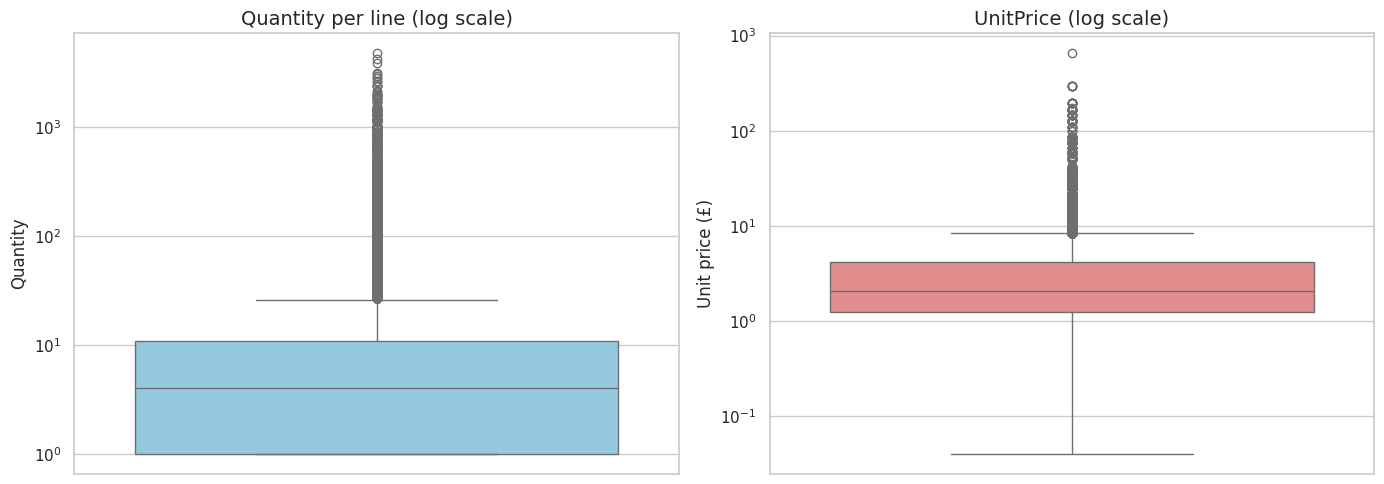

Largest order lines by value (kept as genuine wholesale revenue):


,InvoiceNo,Description,Quantity,UnitPrice,CustomerID,TotalPrice
333860,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,17450.00,7144.72
153504,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.00,6539.40
403769,573003,RABBIT NIGHT LIGHT,2400,2.08,14646.00,4992.00
448192,576365,PAPER CHAIN KIT 50'S CHRISTMAS,688,6.95,NaN,4781.60
153507,550461,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,15749.00,4632.00


Insight: the distributions are heavily right-skewed, which is typical of wholesale trade. Extremes are kept; log scales, quantile scoring and log-transforms are used later instead of capping.
Cleaned data saved to /content/outputs


In [7]:
q1, q3 = df_all['Quantity'].quantile([0.25, 0.75]); iqr_q = q3 - q1
p1, p3 = df_all['UnitPrice'].quantile([0.25, 0.75]); iqr_p = p3 - p1
print(f"Quantity above IQR fence ({q3 + 1.5*iqr_q:.0f}): {(df_all['Quantity'] > q3 + 1.5*iqr_q).sum():,} rows ({(df_all['Quantity'] > q3 + 1.5*iqr_q).mean()*100:.1f}%)")
print(f"UnitPrice above IQR fence ({p3 + 1.5*iqr_p:.2f}): {(df_all['UnitPrice'] > p3 + 1.5*iqr_p).sum():,} rows ({(df_all['UnitPrice'] > p3 + 1.5*iqr_p).mean()*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(ax=axes[0], y=df_all['Quantity'], color='skyblue'); axes[0].set_yscale('log')
axes[0].set_title('Quantity per line (log scale)'); axes[0].set_ylabel('Quantity')
sns.boxplot(ax=axes[1], y=df_all['UnitPrice'], color='lightcoral'); axes[1].set_yscale('log')
axes[1].set_title('UnitPrice (log scale)'); axes[1].set_ylabel('Unit price (£)')
plt.tight_layout(); plt.show()

print("Largest order lines by value (kept as genuine wholesale revenue):")
display(df_all.nlargest(5, 'TotalPrice')[['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'CustomerID', 'TotalPrice']])
print("Insight: the distributions are heavily right-skewed, which is typical of wholesale trade. Extremes are kept; log scales, quantile scoring and log-transforms are used later instead of capping.")

# Save cleaned data
for name, frame in [('df_all', df_all), ('df_cust', df_cust)]:
    try:
        frame.to_parquet(f'{OUT_DIR}/{name}.parquet', index=False)
    except Exception:
        frame.to_csv(f'{OUT_DIR}/{name}.csv.gz', index=False)
df_cancel.to_csv(f'{OUT_DIR}/unmatched_cancellations.csv', index=False)
print("Cleaned data saved to", OUT_DIR)

## Step 4: Feature engineering
Time features plus three analysis tables at invoice, product and customer level.

In [8]:
def add_time_features(frame):
    frame['Year'] = frame['InvoiceDate'].dt.year
    frame['Month'] = frame['InvoiceDate'].dt.month
    frame['YearMonth'] = frame['InvoiceDate'].dt.to_period('M').astype(str)
    frame['Day'] = frame['InvoiceDate'].dt.day
    frame['DayOfWeek'] = frame['InvoiceDate'].dt.day_name()
    frame['Hour'] = frame['InvoiceDate'].dt.hour
    frame['Quarter'] = frame['InvoiceDate'].dt.quarter
    frame['IsWeekend'] = frame['InvoiceDate'].dt.dayofweek.isin([5, 6]).astype(int)
    h = frame['Hour']
    frame['TimeOfDay'] = np.select([h.between(5, 11), h.between(12, 16), h.between(17, 21)],
                                   ['Morning', 'Afternoon', 'Evening'], default='Night')
    return frame

df_all = add_time_features(df_all)
df_cust = add_time_features(df_cust)

invoice_level = df_all.groupby('InvoiceNo').agg(
    CustomerID=('CustomerID', 'first'), InvoiceDate=('InvoiceDate', 'first'),
    NumUniqueItems=('StockCode', 'nunique'), TotalQuantity=('Quantity', 'sum'),
    InvoiceRevenue=('TotalPrice', 'sum'), Country=('Country', 'first')).reset_index()

product_level = df_all.groupby('StockCode').agg(
    Description=('Description', 'first'), TotalQuantitySold=('Quantity', 'sum'),
    TotalRevenue=('TotalPrice', 'sum'), UniqueCustomers=('CustomerID', 'nunique'),
    NumOrders=('InvoiceNo', 'nunique')).reset_index()

customer_level = df_cust.groupby('CustomerID').agg(
    TotalOrders=('InvoiceNo', 'nunique'), TotalItems=('Quantity', 'sum'), TotalRevenue=('TotalPrice', 'sum'),
    FirstPurchaseDate=('InvoiceDate', 'min'), LastPurchaseDate=('InvoiceDate', 'max'),
    NumUniqueProducts=('StockCode', 'nunique'), Country=('Country', 'first')).reset_index()
customer_level['AverageOrderValue'] = customer_level['TotalRevenue'] / customer_level['TotalOrders']
customer_level['AverageBasketSize'] = customer_level['TotalItems'] / customer_level['TotalOrders']
customer_level['CustomerLifetimeDays'] = (customer_level['LastPurchaseDate'] - customer_level['FirstPurchaseDate']).dt.days

for name, frame in [('invoice_level', invoice_level), ('product_level', product_level), ('customer_level', customer_level)]:
    frame.to_csv(f'{OUT_DIR}/{name}.csv', index=False)
    print(f"{name}: {frame.shape}")
    display(frame.head(3))

invoice_level: (19647, 7)


,InvoiceNo,CustomerID,InvoiceDate,NumUniqueItems,TotalQuantity,InvoiceRevenue,Country
0,536365,17850.00,2010-12-01 08:26:00,7,40,139.12,United Kingdom
1,536366,17850.00,2010-12-01 08:28:00,2,12,22.20,United Kingdom
2,536367,13047.00,2010-12-01 08:34:00,12,83,278.73,United Kingdom


product_level: (3907, 6)


,StockCode,Description,TotalQuantitySold,TotalRevenue,UniqueCustomers,NumOrders
0,10002,INFLATABLE POLITICAL GLOBE,860,759.89,40,71
1,10080,GROOVY CACTUS INFLATABLE,303,119.09,19,22
2,10120,DOGGY RUBBER,192,40.32,25,29


customer_level: (4324, 11)


,CustomerID,TotalOrders,TotalItems,TotalRevenue,FirstPurchaseDate,LastPurchaseDate,NumUniqueProducts,Country,AverageOrderValue,AverageBasketSize,CustomerLifetimeDays
0,12347,7,2458,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00,103,Iceland,615.71,351.14,365
1,12348,4,2332,1437.24,2010-12-16 19:09:00,2011-09-25 13:13:00,21,Finland,359.31,583.00,282
2,12349,1,630,1457.55,2011-11-21 09:51:00,2011-11-21 09:51:00,72,Italy,1457.55,630.00,0


## Step 5: Exploratory data analysis
Baseline performance, seasonality, product concentration, geography, customer behaviour and returns. Every "Insight" line below is computed from the data.

In [9]:
# 1. Headline KPIs
total_revenue = df_all['TotalPrice'].sum()
total_orders = df_all['InvoiceNo'].nunique()
unique_customers = df_cust['CustomerID'].nunique()
aov = total_revenue / total_orders
rev_per_customer = df_cust.groupby('CustomerID')['TotalPrice'].sum().mean()
total_units = df_all['Quantity'].sum()

print("=== HEADLINE KPIs (after cleaning, matched cancellations netted) ===")
print(f"Total revenue:                  £{total_revenue:,.2f}")
print(f"Total orders (invoices):        {total_orders:,}")
print(f"Identified customers:           {unique_customers:,}")
print(f"Average order value (AOV):      £{aov:,.2f}")
print(f"Revenue per identified customer: £{rev_per_customer:,.2f}")
print(f"Units sold:                     {total_units:,}")
print(f"Unmatched cancellations (not netted): £{unmatched_cancel_value:,.0f} = {unmatched_cancel_value/total_revenue*100:.1f}% of revenue")
print(f"Revenue without CustomerID:     {df_all.loc[df_all['CustomerID'].isna(), 'TotalPrice'].sum()/total_revenue*100:.1f}% of revenue")

=== HEADLINE KPIs (after cleaning, matched cancellations netted) ===
Total revenue:                  £9,822,108.92
Total orders (invoices):        19,647
Identified customers:           4,324
Average order value (AOV):      £499.93
Revenue per identified customer: £1,922.16
Units sold:                     5,337,342
Unmatched cancellations (not netted): £88,313 = 0.9% of revenue
Revenue without CustomerID:     15.4% of revenue


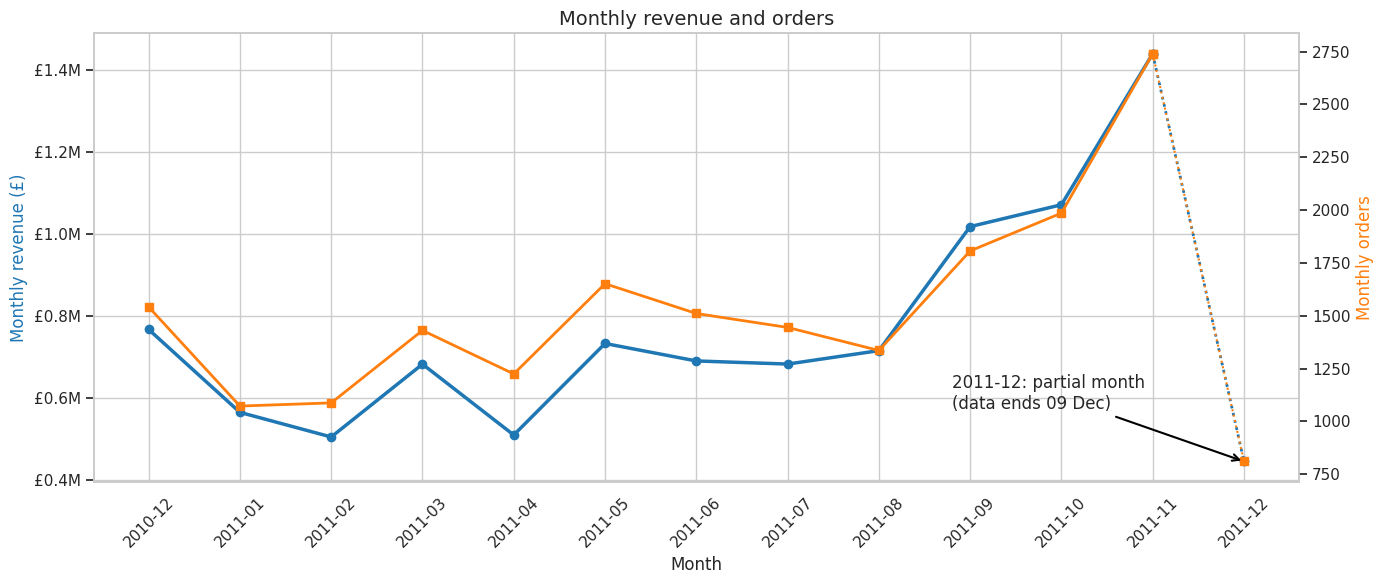

,YearMonth,Revenue,Orders,MoM_Growth_%,Complete
0,2010-12,766996.47,1542,NaN,True
1,2011-01,564792.15,1073,-26.36,True
2,2011-02,504781.58,1088,-10.63,True
3,2011-03,682302.99,1431,35.17,True
4,2011-04,509610.86,1225,-25.31,True
5,2011-05,732720.87,1652,43.78,True
6,2011-06,690147.44,1511,-5.81,True
7,2011-07,682555.64,1445,-1.10,True
8,2011-08,715263.45,1336,4.79,True
9,2011-09,1017666.14,1807,42.28,True


Insight: among complete months, revenue peaks in 2011-11 at £1,439,152 (MoM +34.4%). Revenue in the last three complete months is 1.9x that of the first three months. 2011-12 is incomplete and its MoM change is not meaningful.


In [10]:
# 2. Monthly trend (the last month is incomplete and is flagged)
partial_month = df_all['InvoiceDate'].max().to_period('M').strftime('%Y-%m')
monthly = df_all.groupby('YearMonth').agg(Revenue=('TotalPrice', 'sum'), Orders=('InvoiceNo', 'nunique')).reset_index()
monthly['MoM_Growth_%'] = monthly['Revenue'].pct_change() * 100
monthly['Complete'] = monthly['YearMonth'] != partial_month

fig, ax1 = plt.subplots(figsize=(14, 6))
x = np.arange(len(monthly))
ax1.plot(x[:-1], monthly['Revenue'][:-1], marker='o', color='tab:blue', linewidth=2.5, label='Revenue')
ax1.plot(x[-2:], monthly['Revenue'][-2:], marker='o', color='tab:blue', linestyle=':', linewidth=2)
ax1.set_xticks(x); ax1.set_xticklabels(monthly['YearMonth'], rotation=45)
ax1.set_ylabel('Monthly revenue (£)', color='tab:blue'); ax1.set_xlabel('Month')
ax2 = ax1.twinx()
ax2.plot(x[:-1], monthly['Orders'][:-1], marker='s', color='tab:orange', linewidth=2, label='Orders')
ax2.plot(x[-2:], monthly['Orders'][-2:], marker='s', color='tab:orange', linestyle=':', linewidth=1.5)
ax2.set_ylabel('Monthly orders', color='tab:orange'); ax2.grid(False)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'£{v/1e6:.1f}M'))
ax2.annotate(f'{partial_month}: partial month\n(data ends {df_all["InvoiceDate"].max():%d %b})', xy=(x[-1], monthly['Orders'].iloc[-1]),
             xytext=(x[-1] - 3.2, monthly['Orders'].iloc[-1] + 250), arrowprops=dict(arrowstyle='->', color='black', lw=1.5), zorder=10)
ax1.set_title('Monthly revenue and orders')
plt.tight_layout(); plt.show()

display(monthly)
complete = monthly[monthly['Complete']]
peak = complete.loc[complete['Revenue'].idxmax()]
print(f"Insight: among complete months, revenue peaks in {peak['YearMonth']} at £{peak['Revenue']:,.0f} (MoM {peak['MoM_Growth_%']:+.1f}%). "
      f"Revenue in the last three complete months is {complete['Revenue'].iloc[-3:].sum()/complete['Revenue'].iloc[:3].sum():.1f}x that of the first three months. {partial_month} is incomplete and its MoM change is not meaningful.")

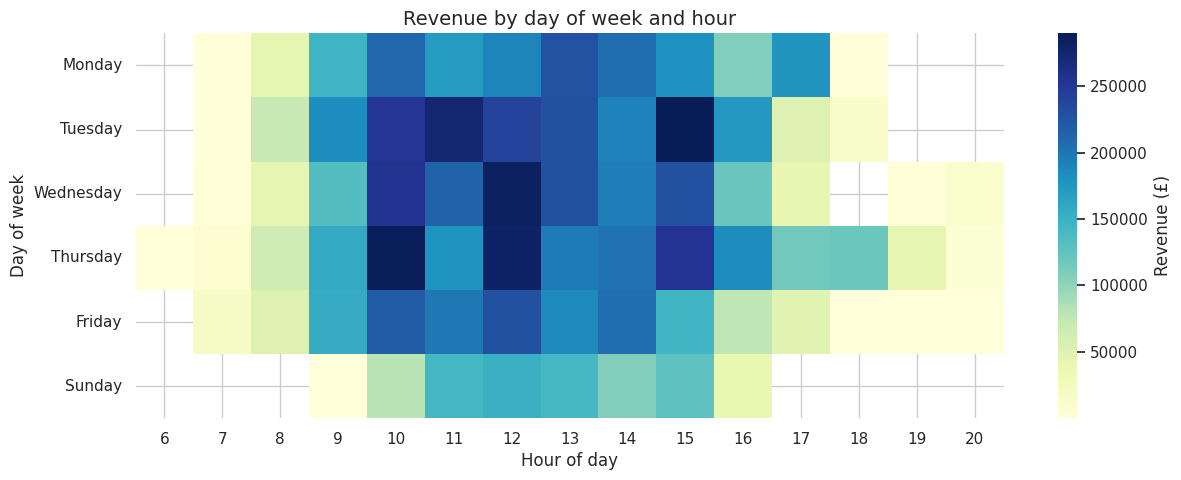

Insight: the busiest day is Thursday (21% of revenue); the busiest hour is 12:00. Hours 9:00-17:00 carry 90% of revenue. No sales are recorded on: Saturday.


In [11]:
# 3. Day-of-week x hour heatmap
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heat = df_all.pivot_table(index='DayOfWeek', columns='Hour', values='TotalPrice', aggfunc='sum')
heat = heat.reindex([d for d in order if d in heat.index])
plt.figure(figsize=(14, 5))
sns.heatmap(heat, cmap='YlGnBu', cbar_kws={'label': 'Revenue (£)'})
plt.title('Revenue by day of week and hour'); plt.xlabel('Hour of day'); plt.ylabel('Day of week')
plt.show()

by_day = df_all.groupby('DayOfWeek')['TotalPrice'].sum().sort_values(ascending=False)
by_hour = df_all.groupby('Hour')['TotalPrice'].sum()
busy_hours = by_hour[by_hour >= 0.5 * by_hour.max()].index
closed_days = [d for d in order if d not in heat.index]
print(f"Insight: the busiest day is {by_day.index[0]} ({by_day.iloc[0]/by_day.sum()*100:.0f}% of revenue); the busiest hour is {by_hour.idxmax()}:00. "
      f"Hours {busy_hours.min()}:00-{busy_hours.max()+1}:00 carry {by_hour.loc[busy_hours].sum()/by_hour.sum()*100:.0f}% of revenue. "
      f"No sales are recorded on: {', '.join(closed_days) if closed_days else 'none'}.")

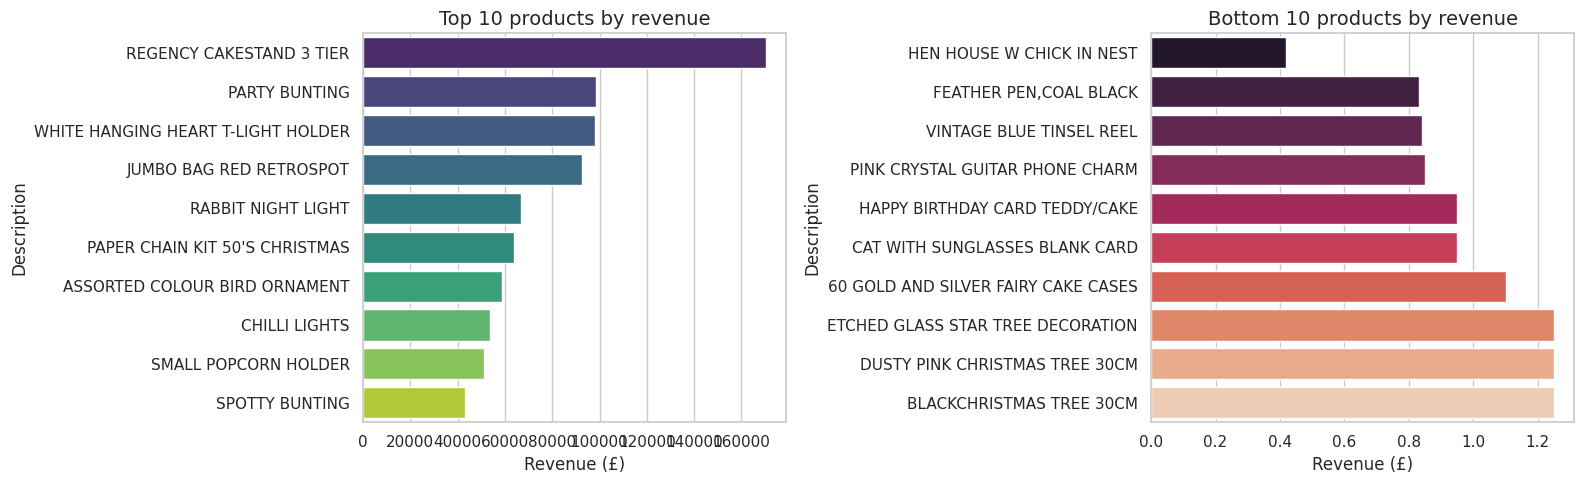

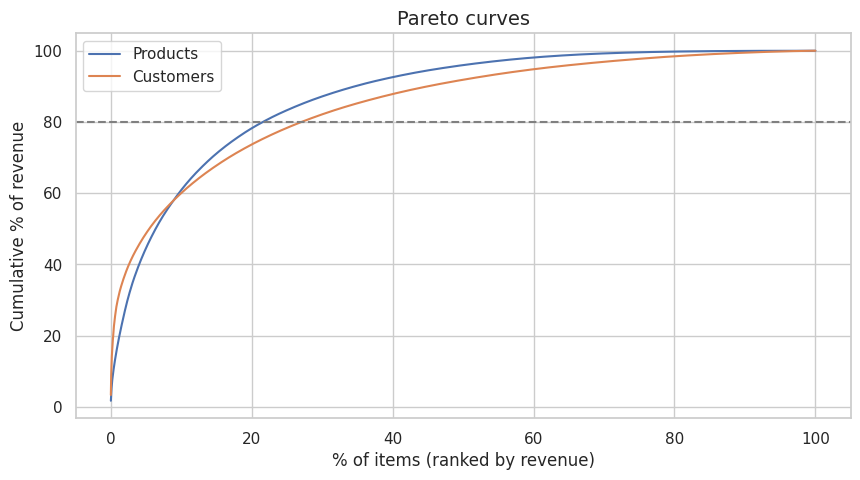

Insight: 21.6% of products (844) generate 80% of product revenue; 27.1% of identified customers (1,171) generate 80% of customer revenue.


In [12]:
# 4. Product concentration (Pareto) and top/bottom products
top_prod = product_level.nlargest(10, 'TotalRevenue')
bot_prod = product_level.nsmallest(10, 'TotalRevenue')
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=top_prod, x='TotalRevenue', y='Description', hue='Description', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Top 10 products by revenue'); axes[0].set_xlabel('Revenue (£)')
sns.barplot(data=bot_prod, x='TotalRevenue', y='Description', hue='Description', palette='rocket', legend=False, ax=axes[1])
axes[1].set_title('Bottom 10 products by revenue'); axes[1].set_xlabel('Revenue (£)')
plt.tight_layout(); plt.show()
print()

def pareto(series):
    s = series.sort_values(ascending=False).reset_index(drop=True)
    cum = s.cumsum() / s.sum() * 100
    n80 = (cum < 80).sum() + 1
    return n80, n80 / len(s) * 100, cum

n_p, pct_p, cum_p = pareto(product_level['TotalRevenue'])
cust_rev = df_cust.groupby('CustomerID')['TotalPrice'].sum()
n_c, pct_c, cum_c = pareto(cust_rev)

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(cum_p)+1)/len(cum_p)*100, cum_p, label='Products')
plt.plot(np.arange(1, len(cum_c)+1)/len(cum_c)*100, cum_c, label='Customers')
plt.axhline(80, color='grey', linestyle='--'); plt.xlabel('% of items (ranked by revenue)'); plt.ylabel('Cumulative % of revenue')
plt.title('Pareto curves'); plt.legend(); plt.show()
print(f"Insight: {pct_p:.1f}% of products ({n_p:,}) generate 80% of product revenue; {pct_c:.1f}% of identified customers ({n_c:,}) generate 80% of customer revenue.")

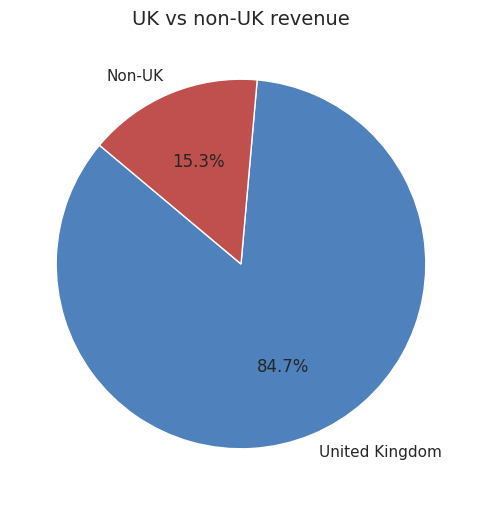

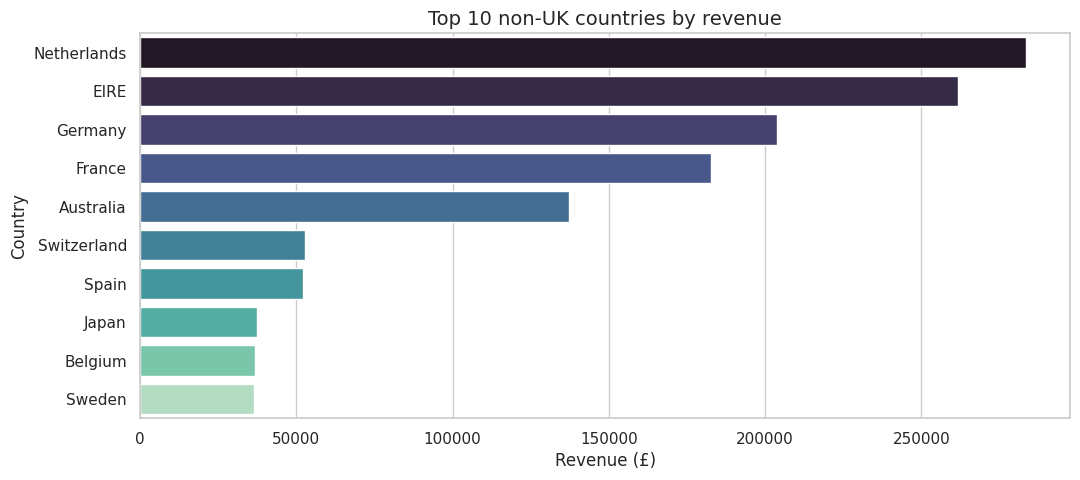

Insight: the UK generates 84.7% of revenue. The largest export markets are Netherlands (£283,444), EIRE (£261,650), Germany (£203,849).


In [13]:
# 5. Country analysis
country_rev = df_all.groupby('Country')['TotalPrice'].sum().reset_index().sort_values('TotalPrice', ascending=False)
uk_rev = country_rev.loc[country_rev['Country'] == 'United Kingdom', 'TotalPrice'].sum()
non_uk = country_rev[country_rev['Country'] != 'United Kingdom']
uk_share = uk_rev / country_rev['TotalPrice'].sum() * 100

plt.figure(figsize=(6, 6))
plt.pie([uk_rev, non_uk['TotalPrice'].sum()], labels=['United Kingdom', 'Non-UK'], autopct='%1.1f%%', colors=['#4F81BD', '#C0504D'], startangle=140)
plt.title('UK vs non-UK revenue'); plt.show()
print()

top_non_uk = non_uk.head(10)
plt.figure(figsize=(12, 5))
sns.barplot(data=top_non_uk, x='TotalPrice', y='Country', hue='Country', palette='mako', legend=False)
plt.title('Top 10 non-UK countries by revenue'); plt.xlabel('Revenue (£)'); plt.ylabel('Country'); plt.show()
t3 = top_non_uk.head(3)
print(f"Insight: the UK generates {uk_share:.1f}% of revenue. The largest export markets are "
      f"{', '.join(f'{c} (£{v:,.0f})' for c, v in zip(t3['Country'], t3['TotalPrice']))}.")

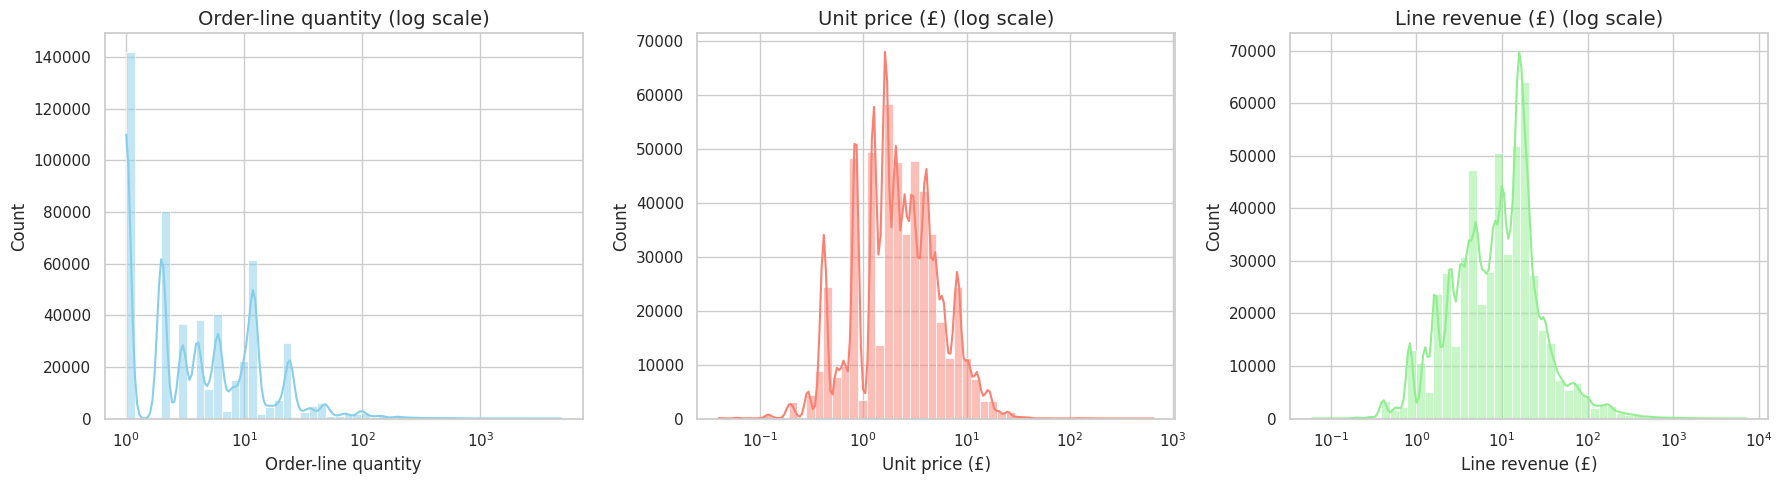

Insight: all three variables are heavily right-skewed (median quantity 4 vs mean 10.3; median line value £9.90 vs mean £18.90), so log scales are needed to see their shape.


In [14]:
# 6. Distributions (log scale)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, color, title in zip(axes, ['Quantity', 'UnitPrice', 'TotalPrice'], ['skyblue', 'salmon', 'lightgreen'],
                                 ['Order-line quantity', 'Unit price (£)', 'Line revenue (£)']):
    sns.histplot(df_all[col], bins=50, kde=True, log_scale=True, color=color, ax=ax)
    ax.set_title(f'{title} (log scale)'); ax.set_xlabel(title)
plt.tight_layout(); plt.show()
print(f"Insight: all three variables are heavily right-skewed (median quantity {df_all['Quantity'].median():.0f} vs mean {df_all['Quantity'].mean():.1f}; "
      f"median line value £{df_all['TotalPrice'].median():.2f} vs mean £{df_all['TotalPrice'].mean():.2f}), so log scales are needed to see their shape.")

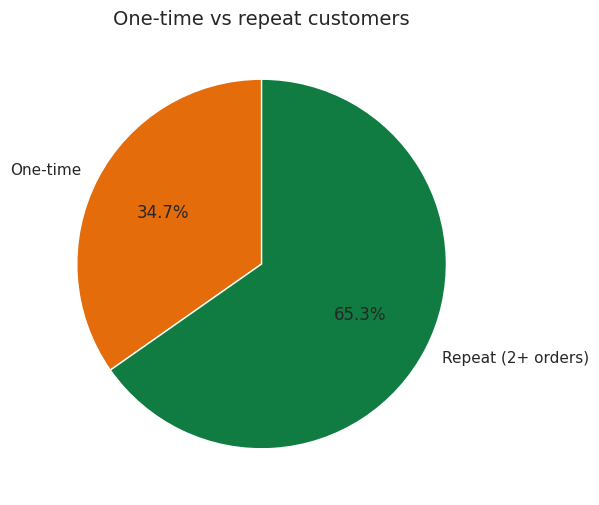

Insight: 65.3% of identified customers placed 2+ orders (median 2, max 203).


In [15]:
# 7. Repeat purchase behaviour
orders_per_cust = customer_level['TotalOrders']
one_time = (orders_per_cust == 1).sum(); repeat = (orders_per_cust > 1).sum()
plt.figure(figsize=(6, 6))
plt.pie([one_time, repeat], labels=['One-time', 'Repeat (2+ orders)'], autopct='%1.1f%%', colors=['#E46C0A', '#107C41'], startangle=90)
plt.title('One-time vs repeat customers'); plt.show()
print(f"Insight: {repeat/len(orders_per_cust)*100:.1f}% of identified customers placed 2+ orders (median {orders_per_cust.median():.0f}, max {orders_per_cust.max()}).")

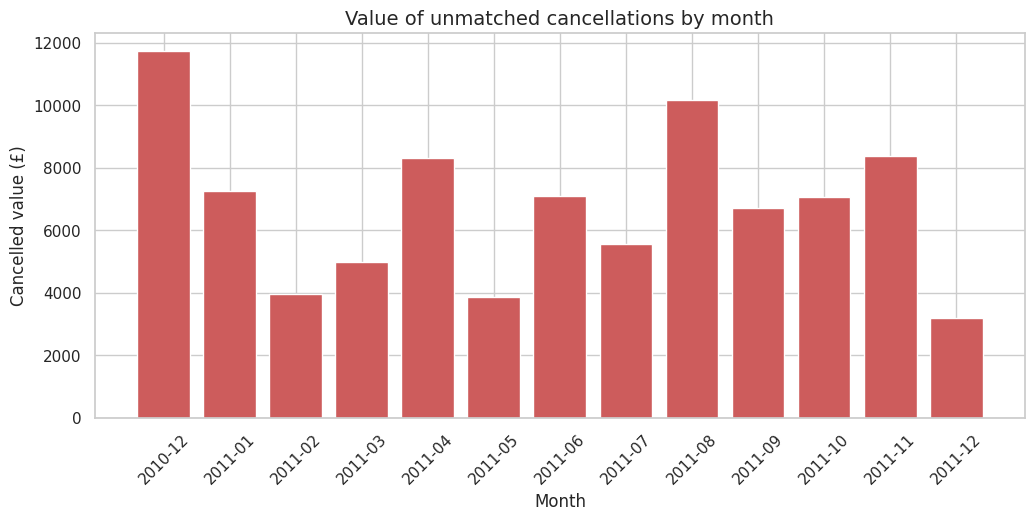

Top 5 products by value of unmatched cancellations:


,UnitsReturned,ValueReturned,Lines
Description,,,
REGENCY CAKESTAND 3 TIER,509,5764.35,137
TEA TIME PARTY BUNTING,1371,3490.60,5
COLOUR GLASS. STAR T-LIGHT HOLDER,1173,3242.91,23
IVORY DINER WALL CLOCK,332,2551.70,10
ROUND SNACK BOXES SET OF 4 FRUITS,647,1659.05,14


Insight: 2,818 cancellations were exact reversals of earlier orders and are netted out (including the two giant mistaken orders). The remaining unmatched cancellations (partial returns and credits) total £88,313, about 0.9% of revenue; the highest month is 2010-12.


In [16]:
# 8. Returns: cancellations that could not be matched to a sale
df_cancel = df_cancel.copy()
df_cancel['YearMonth'] = df_cancel['InvoiceDate'].dt.to_period('M').astype(str)
df_cancel['UnitsCancelled'] = -df_cancel['Quantity']
df_cancel['ValueCancelled'] = -df_cancel['Quantity'] * df_cancel['UnitPrice']
cancel_monthly = df_cancel.groupby('YearMonth')[['UnitsCancelled', 'ValueCancelled']].sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(cancel_monthly['YearMonth'], cancel_monthly['ValueCancelled'], color='indianred')
ax.set_title('Value of unmatched cancellations by month'); ax.set_xlabel('Month'); ax.set_ylabel('Cancelled value (£)')
plt.xticks(rotation=45); plt.show()

returned = df_cancel.groupby('Description').agg(UnitsReturned=('UnitsCancelled', 'sum'), ValueReturned=('ValueCancelled', 'sum'),
                                                Lines=('InvoiceNo', 'count')).sort_values('ValueReturned', ascending=False).head(5)
print("Top 5 products by value of unmatched cancellations:")
display(returned)
share = cancel_monthly['ValueCancelled'].sum() / total_revenue * 100
print(f"Insight: {len(matched_sales):,} cancellations were exact reversals of earlier orders and are netted out (including the two giant mistaken orders). "
      f"The remaining unmatched cancellations (partial returns and credits) total £{cancel_monthly['ValueCancelled'].sum():,.0f}, about {share:.1f}% of revenue; "
      f"the highest month is {cancel_monthly.loc[cancel_monthly['ValueCancelled'].idxmax(), 'YearMonth']}.")

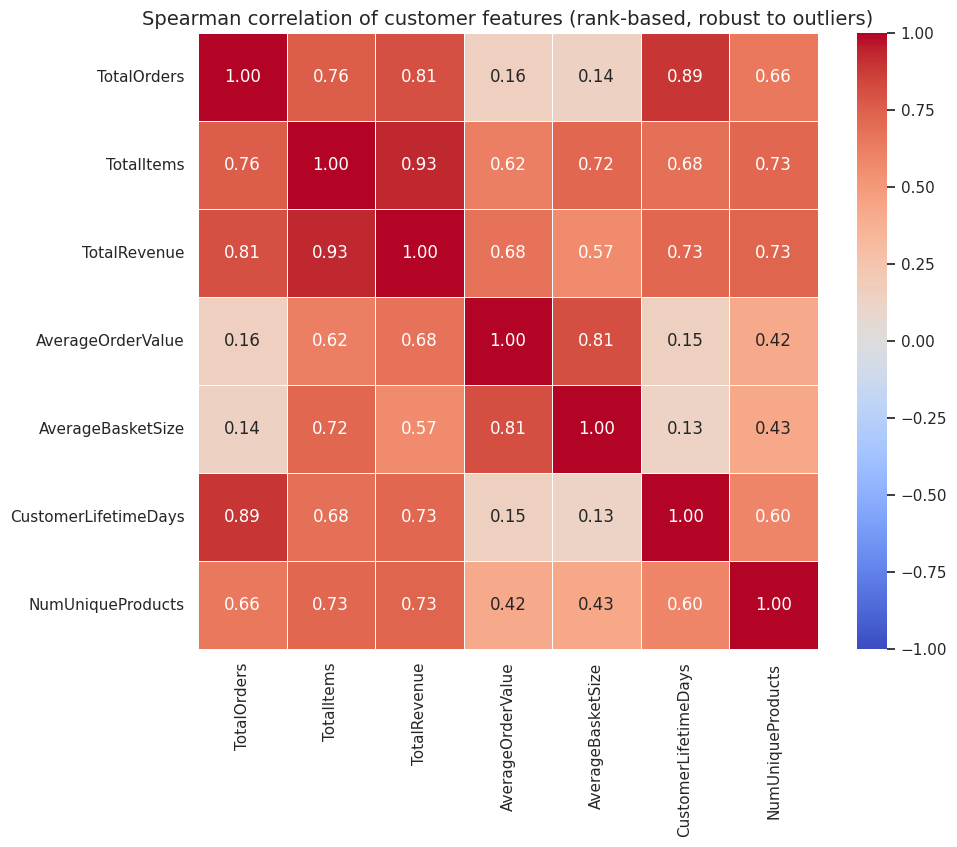

Insight: the strongest rank correlations are TotalItems vs TotalRevenue (0.93) and TotalOrders vs CustomerLifetimeDays (0.89).


In [17]:
# 9. Correlations between customer-level features
num_cols = ['TotalOrders', 'TotalItems', 'TotalRevenue', 'AverageOrderValue', 'AverageBasketSize', 'CustomerLifetimeDays', 'NumUniqueProducts']
corr = customer_level[num_cols].corr(method='spearman')
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Spearman correlation of customer features (rank-based, robust to outliers)'); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(f"Insight: the strongest rank correlations are {pairs.index[0][0]} vs {pairs.index[0][1]} ({pairs.iloc[0]:.2f}) and "
      f"{pairs.index[1][0]} vs {pairs.index[1][1]} ({pairs.iloc[1]:.2f}).")

### Key EDA findings
Quantified results for the points below are printed in the "Insight" lines above and collected again in the executive summary at the end of the notebook:
- Revenue is dominated by a minority of products and customers (Pareto effect).
- Sales rise through autumn and peak in November; December 2011 is incomplete.
- Trading happens on weekdays during business hours, with no Saturday sales.
- The UK is by far the largest market; the Netherlands, EIRE, Germany and France lead exports.
- Most identified customers order more than once.
- Giant order-then-cancel pairs were netted out; the remaining unmatched cancellations are small relative to revenue.

## Step 6: RFM segmentation
**Recency** (days since last purchase), **Frequency** (distinct invoices) and **Monetary** (total spend) are scored 1–5 by quantile and mapped to named segments. The snapshot date is one day after the last transaction.

Snapshot date: 2011-12-10 12:50:00


,Recency,Frequency,Monetary
count,4324.00,4324.00,4324.00
mean,92.83,4.23,1922.16
std,100.26,7.57,8311.07
min,1.00,1.00,2.90
25%,18.00,1.00,301.23
50%,51.00,2.00,656.43
75%,143.00,5.00,1615.05
max,374.00,203.00,278742.02


Recency skewness: 1.24
Frequency skewness: 11.84
Monetary skewness: 21.50


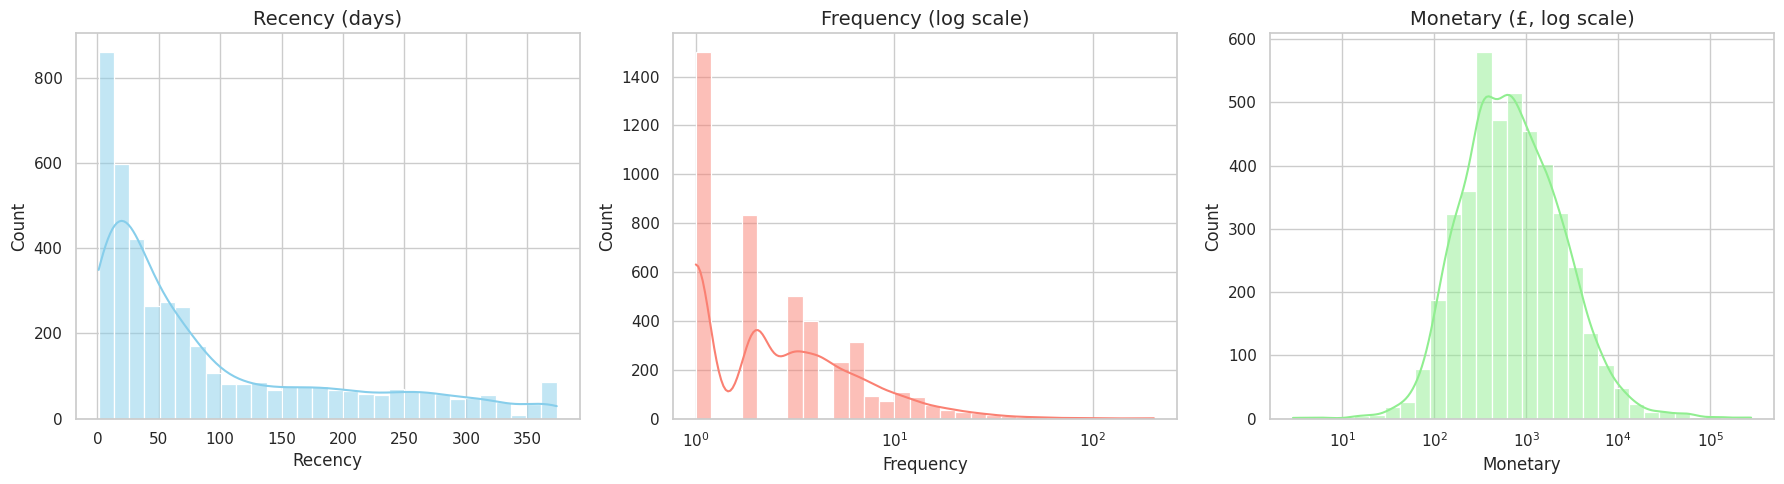

Insight: Frequency and Monetary are extremely skewed, so quantile scores (rather than raw cut-offs) are used to split customers evenly.


In [18]:
snapshot_date = df_cust['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

rfm = df_cust.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')).reset_index()

display(rfm[['Recency', 'Frequency', 'Monetary']].describe())
for c in ['Recency', 'Frequency', 'Monetary']:
    print(f"{c} skewness: {rfm[c].skew():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(rfm['Recency'], bins=30, kde=True, color='skyblue', ax=axes[0]); axes[0].set_title('Recency (days)')
sns.histplot(rfm['Frequency'], bins=30, kde=True, log_scale=True, color='salmon', ax=axes[1]); axes[1].set_title('Frequency (log scale)')
sns.histplot(rfm['Monetary'], bins=30, kde=True, log_scale=True, color='lightgreen', ax=axes[2]); axes[2].set_title('Monetary (£, log scale)')
plt.tight_layout(); plt.show()
print("Insight: Frequency and Monetary are extremely skewed, so quantile scores (rather than raw cut-offs) are used to split customers evenly.")

In [19]:
# Quantile scores: Recency reversed (recent = 5); rank(method='first') avoids duplicate bin edges for Frequency
rfm['R'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1])
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])
rfm['M'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5])
rfm['RFM_Score'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)
rfm['RFM_Total'] = rfm[['R', 'F', 'M']].astype(int).sum(axis=1)

# Standard segment map on the R and F scores
segs_map = {
    r'[1-2][1-2]': 'Hibernating',
    r'[1-2][3-4]': 'At Risk',
    r'[1-2]5': "Can't Lose Them",
    r'3[1-2]': 'About To Sleep',
    r'33': 'Need Attention',
    r'[3-4][4-5]': 'Loyal Customers',
    r'41': 'Promising',
    r'51': 'New Customers',
    r'[4-5][2-3]': 'Potential Loyalists',
    r'5[4-5]': 'Champions'
}
rfm['Segment'] = (rfm['R'].astype(str) + rfm['F'].astype(str)).replace(segs_map, regex=True)
assert rfm['Segment'].isin(segs_map.values()).all(), "Some customers were not mapped to a segment"

seg_profile = rfm.groupby('Segment').agg(Customers=('CustomerID', 'count'), AvgRecency=('Recency', 'mean'),
                                         AvgFrequency=('Frequency', 'mean'), AvgMonetary=('Monetary', 'mean'),
                                         Revenue=('Monetary', 'sum')).sort_values('Revenue', ascending=False)
seg_profile['% Customers'] = seg_profile['Customers'] / len(rfm) * 100
seg_profile['% Revenue'] = seg_profile['Revenue'] / rfm['Monetary'].sum() * 100
print("RFM segment profile (sorted by revenue):")
display(seg_profile)
rfm.to_csv(f'{OUT_DIR}/rfm.csv', index=False)
print("Saved", f'{OUT_DIR}/rfm.csv')

RFM segment profile (sorted by revenue):


,Customers,AvgRecency,AvgFrequency,AvgMonetary,Revenue,% Customers,% Revenue
Segment,,,,,,,
Champions,639,6.03,12.22,6597.36,4215716.06,14.78,50.72
Loyal Customers,816,33.76,6.36,2768.12,2258785.33,18.87,27.18
At Risk,575,154.37,2.85,937.41,539008.77,13.30,6.49
Hibernating,1068,218.58,1.10,411.96,439975.49,24.70,5.29
Potential Loyalists,491,17.11,2.01,673.58,330727.88,11.36,3.98
Can't Lose Them,62,135.06,8.27,2761.81,171232.41,1.43,2.06
About To Sleep,345,53.61,1.14,444.57,153375.57,7.98,1.85
Need Attention,186,53.10,2.31,819.67,152459.07,4.30,1.83
Promising,99,23.48,1.00,346.33,34287.07,2.29,0.41


Saved /content/outputs/rfm.csv


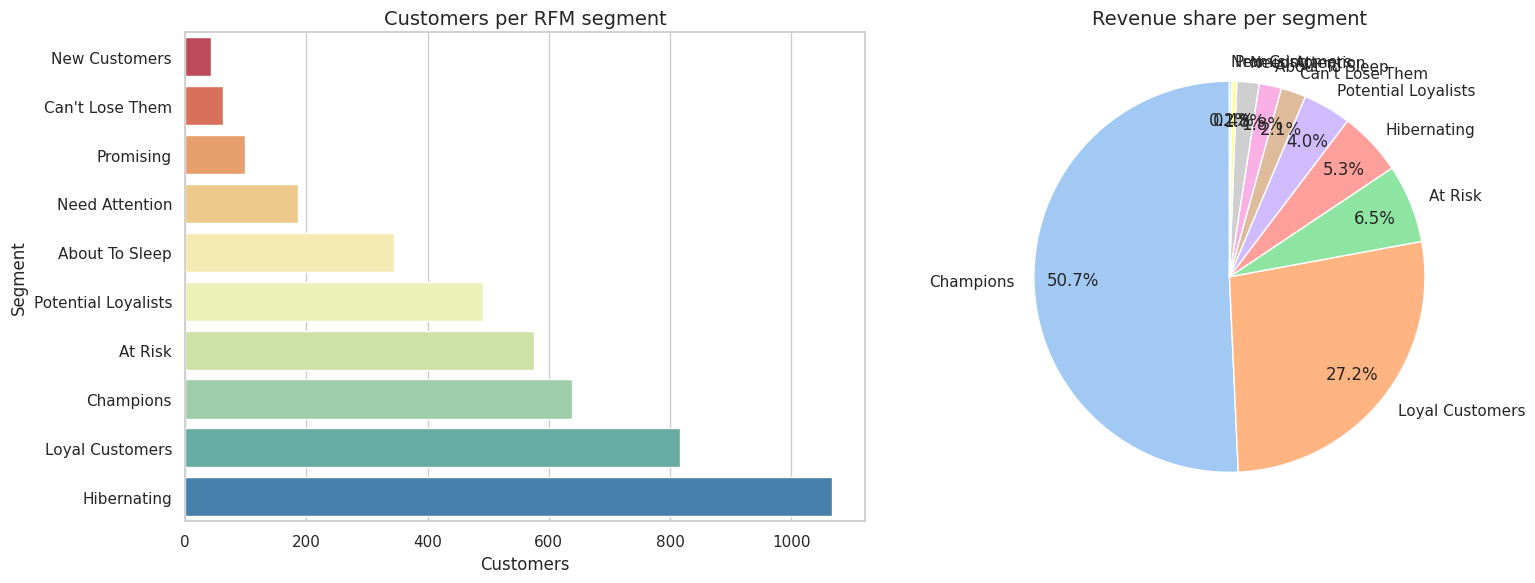

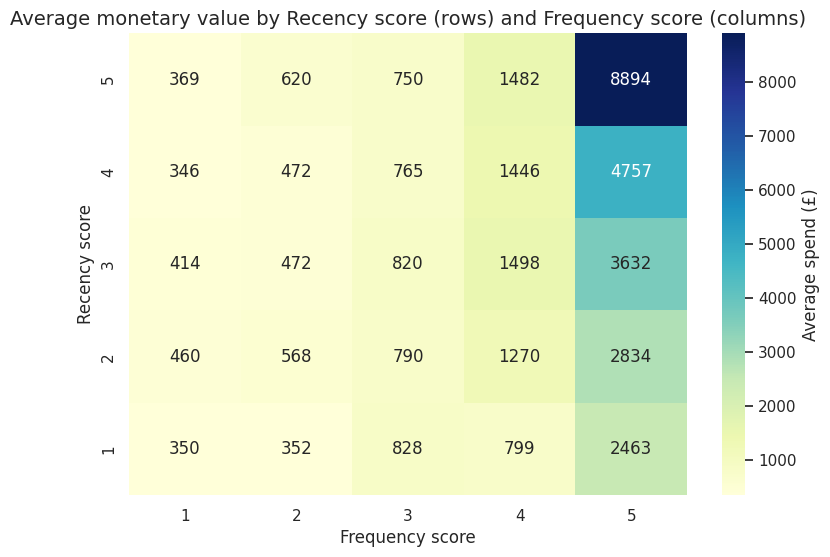

Insight: Champions are 14.8% of identified customers but 50.7% of revenue. Together with Loyal Customers, the top two segments hold 77.9% of revenue. The three lapsing segments (At Risk, Can't Lose Them, Hibernating) make up 39.4% of customers but only 13.8% of revenue.


In [20]:
# Segment visuals
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=seg_profile.reset_index().sort_values('Customers'), x='Customers', y='Segment', hue='Segment', palette='Spectral', legend=False, ax=axes[0])
axes[0].set_title('Customers per RFM segment')
rev = seg_profile['% Revenue'].sort_values(ascending=False)
axes[1].pie(rev, labels=rev.index, autopct='%1.1f%%', colors=sns.color_palette('pastel', len(rev)), startangle=90, pctdistance=0.8)
axes[1].set_title('Revenue share per segment')
plt.tight_layout(); plt.show()
print()

heat_rf = rfm.pivot_table(index='R', columns='F', values='Monetary', aggfunc='mean', observed=True)
plt.figure(figsize=(9, 6))
sns.heatmap(heat_rf, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Average spend (£)'})
plt.title('Average monetary value by Recency score (rows) and Frequency score (columns)')
plt.xlabel('Frequency score'); plt.ylabel('Recency score'); plt.show()

top_seg = seg_profile.index[0]
lapsing = [s for s in ['At Risk', "Can't Lose Them", 'Hibernating'] if s in seg_profile.index]
print(f"Insight: {top_seg} are {seg_profile.loc[top_seg, '% Customers']:.1f}% of identified customers but {seg_profile.loc[top_seg, '% Revenue']:.1f}% of revenue. "
      f"Together with {seg_profile.index[1]}, the top two segments hold {seg_profile['% Revenue'].iloc[:2].sum():.1f}% of revenue. "
      f"The three lapsing segments ({', '.join(lapsing)}) make up {seg_profile.loc[lapsing, '% Customers'].sum():.1f}% of customers "
      f"but only {seg_profile.loc[lapsing, '% Revenue'].sum():.1f}% of revenue.")

In [21]:
# Interactive treemap of segment sizes (Plotly)
seg_sizes = seg_profile.reset_index()[['Segment', 'Customers']]
fig = px.treemap(seg_sizes, path=['Segment'], values='Customers', color='Customers',
                 color_continuous_scale='RdYlGn', title='Treemap of RFM segments (by customers)')
fig.show()

### Segment profiles and recommended actions
| Segment | Who they are | Recommended action |
| :--- | :--- | :--- |
| **Champions** | Bought recently, often, and spend the most | VIP programme, early access to new products, dedicated support |
| **Loyal Customers** | Regular, responsive buyers | Cross-sell related products, ask for reviews, bundle offers |
| **Potential Loyalists** | Recent buyers with moderate frequency | Personalised upsell, loyalty challenges |
| **New Customers** | Very recent first purchase | Welcome sequence, time-limited second-purchase offer |
| **Promising** | Recent but low-spend | Low-threshold vouchers to encourage a second order |
| **Need Attention** | Middling recency and frequency | Limited-time offers to re-engage |
| **About To Sleep** | Below-average recency and frequency | Win-back emails featuring popular products |
| **At Risk** | Used to buy regularly but have lapsed | Personalised reactivation discounts, satisfaction survey |
| **Can't Lose Them** | Historically frequent and high value, now absent | Direct outreach, exclusive comeback credit |
| **Hibernating** | Low across all three dimensions | Low-cost retargeting only |

## Step 7: Customer segmentation with K-Means
RFM scores use fixed cut-offs. K-Means finds natural groups in the data instead. Because R, F and M are skewed, we apply `log1p` and standardise before clustering.

In [22]:
rfm_ml = rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary']].copy()
rfm_log = np.log1p(rfm_ml[['Recency', 'Frequency', 'Monetary']])
scaler = StandardScaler()
rfm_scaled = pd.DataFrame(scaler.fit_transform(rfm_log), columns=['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled'], index=rfm_ml['CustomerID'])
display(rfm_scaled.head())
for c in rfm_scaled.columns:
    print(f"{c} skewness after log + scaling: {rfm_scaled[c].skew():.2f}")

,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
CustomerID,,,
12347,-2.04,1.09,1.44
12348,0.37,0.40,0.57
12349,-0.63,-0.95,0.58
12350,1.42,-0.95,-0.70
12352,-0.17,0.89,0.47


Recency_Scaled skewness after log + scaling: -0.38
Frequency_Scaled skewness after log + scaling: 1.22
Monetary_Scaled skewness after log + scaling: 0.35


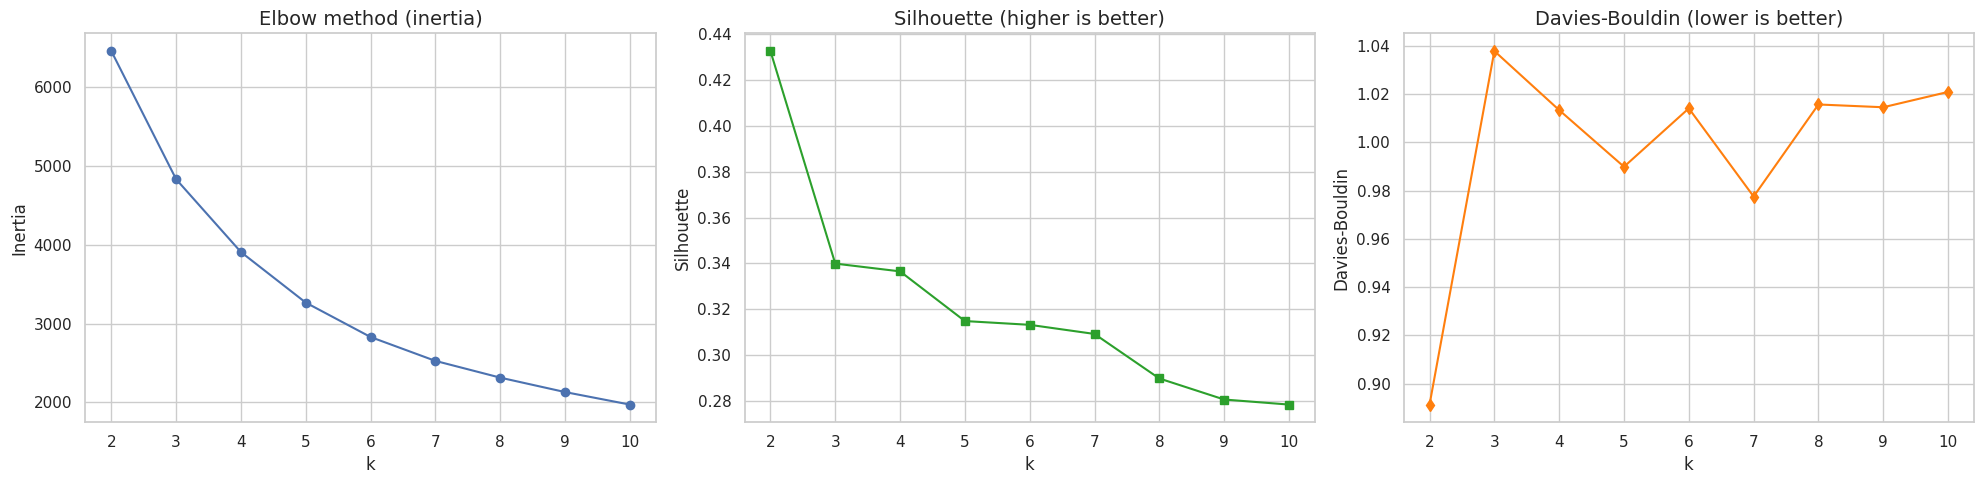

,k,Inertia,Silhouette,Davies-Bouldin
0,2,6458.08,0.43,0.89
1,3,4831.75,0.34,1.04
2,4,3907.63,0.34,1.01
3,5,3266.36,0.31,0.99
4,6,2829.83,0.31,1.01
5,7,2527.01,0.31,0.98
6,8,2314.59,0.29,1.02
7,9,2131.55,0.28,1.01
8,10,1972.81,0.28,1.02


Best silhouette: k=2; lowest Davies-Bouldin: k=2


In [23]:
# Choose k: elbow, silhouette, Davies-Bouldin for k = 2..10
K_range = range(2, 11)
sse, sil, dbi = [], [], []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(rfm_scaled)
    sse.append(km.inertia_); sil.append(silhouette_score(rfm_scaled, km.labels_)); dbi.append(davies_bouldin_score(rfm_scaled, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(K_range, sse, marker='o'); axes[0].set_title('Elbow method (inertia)'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].plot(K_range, sil, marker='s', color='tab:green'); axes[1].set_title('Silhouette (higher is better)'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
axes[2].plot(K_range, dbi, marker='d', color='tab:orange'); axes[2].set_title('Davies-Bouldin (lower is better)'); axes[2].set_xlabel('k'); axes[2].set_ylabel('Davies-Bouldin')
plt.tight_layout(); plt.show()

k_metrics = pd.DataFrame({'k': list(K_range), 'Inertia': sse, 'Silhouette': sil, 'Davies-Bouldin': dbi})
display(k_metrics)
print(f"Best silhouette: k={k_metrics.loc[k_metrics['Silhouette'].idxmax(), 'k']}; lowest Davies-Bouldin: k={k_metrics.loc[k_metrics['Davies-Bouldin'].idxmin(), 'k']}")

### Choice of k
The metrics printed above favour **k = 2** (highest silhouette, lowest Davies-Bouldin), but the inertia curve shows no sharp elbow, and two clusters would only separate "valuable" from "not valuable". We use **k = 3** as a deliberate trade-off: it still gives well-separated groups while allowing three distinct strategies (a VIP group, an active mid-value group and a lapsed low-value group). The k = 3 scores are lower than k = 2, so the result should be read as a useful business grouping rather than a sharp natural split.

In [24]:
# Fit k = 3 and name clusters from their profiles (never hard-coded)
kmeans_final = KMeans(n_clusters=3, random_state=SEED, n_init=10)
rfm_ml['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

raw_profile = rfm_ml.groupby('Cluster').agg(Size=('CustomerID', 'count'), Recency=('Recency', 'mean'),
                                            Frequency=('Frequency', 'mean'), Monetary=('Monetary', 'mean'))
vip_cluster = raw_profile['Monetary'].idxmax()
lapsed_cluster = raw_profile.drop(index=vip_cluster)['Recency'].idxmax()
active_cluster = [c for c in raw_profile.index if c not in (vip_cluster, lapsed_cluster)][0]
cluster_names = {vip_cluster: 'High-Value VIPs', active_cluster: 'Active Mid-Spenders', lapsed_cluster: 'Lapsed Low-Spenders'}
CLUSTER_ORDER = ['High-Value VIPs', 'Active Mid-Spenders', 'Lapsed Low-Spenders']
CLUSTER_COLORS = {'High-Value VIPs': '#2a9d8f', 'Active Mid-Spenders': '#e9c46a', 'Lapsed Low-Spenders': '#e76f51'}
rfm_ml['Cluster_Name'] = rfm_ml['Cluster'].map(cluster_names)

cluster_profiles = (rfm_ml.groupby('Cluster_Name').agg(Customers=('CustomerID', 'count'), AvgRecency=('Recency', 'mean'),
                    AvgFrequency=('Frequency', 'mean'), AvgMonetary=('Monetary', 'mean'), Revenue=('Monetary', 'sum'))
                    .reindex(CLUSTER_ORDER))
cluster_profiles['% Customers'] = cluster_profiles['Customers'] / len(rfm_ml) * 100
cluster_profiles['% Revenue'] = cluster_profiles['Revenue'] / rfm_ml['Monetary'].sum() * 100
print("Cluster profiles (original units):")
display(cluster_profiles)
vip = cluster_profiles.loc['High-Value VIPs']
print(f"Insight: the High-Value VIP cluster is {vip['% Customers']:.1f}% of customers and {vip['% Revenue']:.1f}% of revenue "
      f"(average {vip['AvgFrequency']:.1f} orders, last seen {vip['AvgRecency']:.0f} days before the snapshot).")

Cluster profiles (original units):


,Customers,AvgRecency,AvgFrequency,AvgMonetary,Revenue,% Customers,% Revenue
Cluster_Name,,,,,,,
High-Value VIPs,731,16.08,13.56,7590.28,5548494.28,16.91,66.76
Active Mid-Spenders,1696,43.38,3.42,1228.95,2084306.45,39.22,25.08
Lapsed Low-Spenders,1897,166.61,1.35,357.74,678630.70,43.87,8.17


Insight: the High-Value VIP cluster is 16.9% of customers and 66.8% of revenue (average 13.6 orders, last seen 16 days before the snapshot).


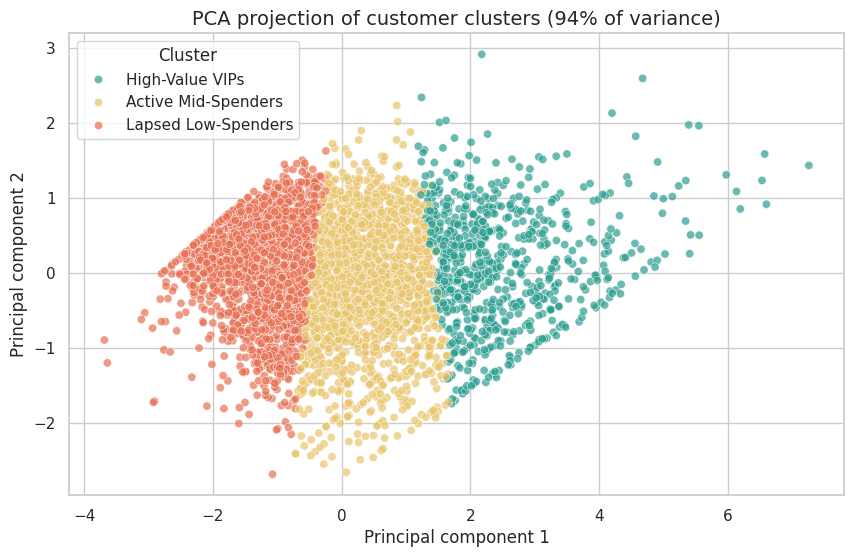

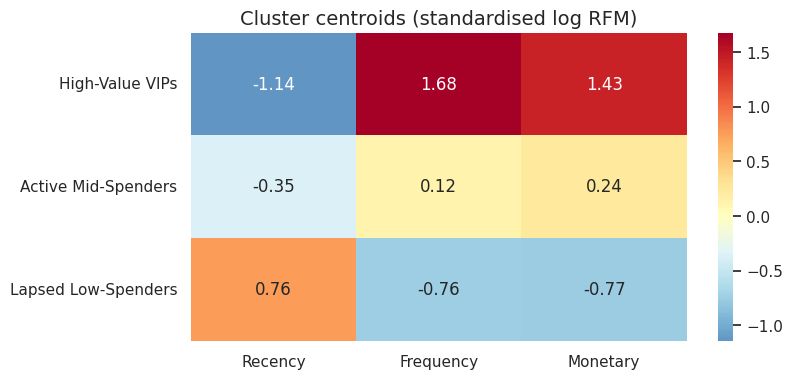

In [25]:
# 2D PCA projection and centroid heatmap
pca = PCA(n_components=2, random_state=SEED)
comp = pca.fit_transform(rfm_scaled)
rfm_pca = pd.DataFrame(comp, columns=['PCA1', 'PCA2']); rfm_pca['Cluster'] = rfm_ml['Cluster_Name'].values

plt.figure(figsize=(10, 6))
sns.scatterplot(data=rfm_pca, x='PCA1', y='PCA2', hue='Cluster', hue_order=CLUSTER_ORDER, palette=CLUSTER_COLORS, alpha=0.7)
plt.title(f'PCA projection of customer clusters ({pca.explained_variance_ratio_.sum()*100:.0f}% of variance)')
plt.xlabel('Principal component 1'); plt.ylabel('Principal component 2'); plt.legend(title='Cluster'); plt.show()
print()

centroids = pd.DataFrame(kmeans_final.cluster_centers_, columns=['Recency', 'Frequency', 'Monetary'])
centroids.index = centroids.index.map(cluster_names)
plt.figure(figsize=(8, 4))
sns.heatmap(centroids.reindex(CLUSTER_ORDER), annot=True, cmap='RdYlBu_r', center=0, fmt='.2f')
plt.title('Cluster centroids (standardised log RFM)'); plt.ylabel(''); plt.show()

In [26]:
# 3D view (Plotly, log axes)
fig_3d = px.scatter_3d(rfm_ml, x='Recency', y='Frequency', z='Monetary', color='Cluster_Name',
                       category_orders={'Cluster_Name': CLUSTER_ORDER}, color_discrete_map=CLUSTER_COLORS,
                       log_x=True, log_y=True, log_z=True, title='3D view of customer clusters (log axes)')
fig_3d.update_layout(margin=dict(l=0, r=0, b=0, t=50))
fig_3d.show()

In [27]:
# Compare K-Means with hierarchical clustering and DBSCAN on a 2,000-customer sample.
# A FRESH KMeans is used here so the final model above is not modified.
sample = rfm_scaled.sample(n=min(2000, len(rfm_scaled)), random_state=SEED)
km_s = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit_predict(sample)
agg_s = AgglomerativeClustering(n_clusters=3).fit_predict(sample)
db_s = DBSCAN(eps=0.8, min_samples=10).fit_predict(sample)

def score(labels):
    mask = labels != -1                                   # exclude DBSCAN noise points from the scores
    if len(set(labels[mask])) < 2:
        return np.nan, np.nan
    return silhouette_score(sample[mask], labels[mask]), davies_bouldin_score(sample[mask], labels[mask])

rows = []
for name, lab in [('K-Means (k=3)', km_s), ('Agglomerative (k=3)', agg_s), ('DBSCAN', db_s)]:
    s_, d_ = score(lab)
    rows.append({'Algorithm': name, 'Clusters': len(set(lab) - {-1}), 'Noise points': int((lab == -1).sum()), 'Silhouette': s_, 'Davies-Bouldin': d_})
display(pd.DataFrame(rows))
print("Note: DBSCAN scores are computed on non-noise points only and it assigns a share of customers to noise, "
      "so its numbers are not directly comparable with the partitioning methods.")

,Algorithm,Clusters,Noise points,Silhouette,Davies-Bouldin
0,K-Means (k=3),3,0,0.34,1.03
1,Agglomerative (k=3),3,0,0.31,1.09
2,DBSCAN,1,17,NaN,NaN


Note: DBSCAN scores are computed on non-noise points only and it assigns a share of customers to noise, so its numbers are not directly comparable with the partitioning methods.


In [28]:
# Cross-tabulate K-Means clusters against rule-based RFM segments
rfm_ml['Rule_Based_Segment'] = rfm['Segment'].values
cross = pd.crosstab(rfm_ml['Rule_Based_Segment'], rfm_ml['Cluster_Name'])[CLUSTER_ORDER]
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100
print("Customers (counts):"); display(cross)
print("Row percentages (where each RFM segment sits in the K-Means clusters):"); display(cross_pct.round(1))

print("Main cluster of each RFM segment:")
for seg in cross_pct.index:
    top = cross_pct.loc[seg].sort_values(ascending=False)
    extra = f", {top.iloc[1]:.0f}% {top.index[1]}" if top.iloc[1] >= 1 else ""
    print(f"  {seg}: {top.iloc[0]:.0f}% {top.index[0]}{extra}")
purity = cross.max(axis=1).sum() / cross.values.sum() * 100
print(f"\nInsight: {purity:.0f}% of customers sit in their RFM segment's dominant cluster, so the rule-based and K-Means views largely agree.")

rfm_ml.to_csv(f'{OUT_DIR}/customer_segments.csv', index=False)
print("Saved", f'{OUT_DIR}/customer_segments.csv')

Customers (counts):


Cluster_Name,High-Value VIPs,Active Mid-Spenders,Lapsed Low-Spenders
Rule_Based_Segment,,,
About To Sleep,0,56,289
At Risk,0,231,344
Can't Lose Them,18,42,2
Champions,466,173,0
Hibernating,0,29,1039
Loyal Customers,245,566,5
Need Attention,0,126,60
New Customers,0,38,5
Potential Loyalists,2,409,80


Row percentages (where each RFM segment sits in the K-Means clusters):


Cluster_Name,High-Value VIPs,Active Mid-Spenders,Lapsed Low-Spenders
Rule_Based_Segment,,,
About To Sleep,0.00,16.20,83.80
At Risk,0.00,40.20,59.80
Can't Lose Them,29.00,67.70,3.20
Champions,72.90,27.10,0.00
Hibernating,0.00,2.70,97.30
Loyal Customers,30.00,69.40,0.60
Need Attention,0.00,67.70,32.30
New Customers,0.00,88.40,11.60
Potential Loyalists,0.40,83.30,16.30


Main cluster of each RFM segment:
  About To Sleep: 84% Lapsed Low-Spenders, 16% Active Mid-Spenders
  At Risk: 60% Lapsed Low-Spenders, 40% Active Mid-Spenders
  Can't Lose Them: 68% Active Mid-Spenders, 29% High-Value VIPs
  Champions: 73% High-Value VIPs, 27% Active Mid-Spenders
  Hibernating: 97% Lapsed Low-Spenders, 3% Active Mid-Spenders
  Loyal Customers: 69% Active Mid-Spenders, 30% High-Value VIPs
  Need Attention: 68% Active Mid-Spenders, 32% Lapsed Low-Spenders
  New Customers: 88% Active Mid-Spenders, 12% Lapsed Low-Spenders
  Potential Loyalists: 83% Active Mid-Spenders, 16% Lapsed Low-Spenders
  Promising: 74% Lapsed Low-Spenders, 26% Active Mid-Spenders

Insight: 78% of customers sit in their RFM segment's dominant cluster, so the rule-based and K-Means views largely agree.
Saved /content/outputs/customer_segments.csv


## Step 8: Cohort and retention analysis
Customers are grouped by the month of their first purchase and tracked month by month.

Two corrections matter here:
- **December 2011 is excluded** because the month is incomplete (it would create a false drop at the end of every cohort).
- **The December 2010 cohort is labelled "existing customers".** The data starts in December 2010, so that cohort contains customers who were already buying before the dataset begins, not genuinely new customers. It is analysed separately.

Retention in month *k* = share of the cohort that placed at least one order in month *k* after their first.

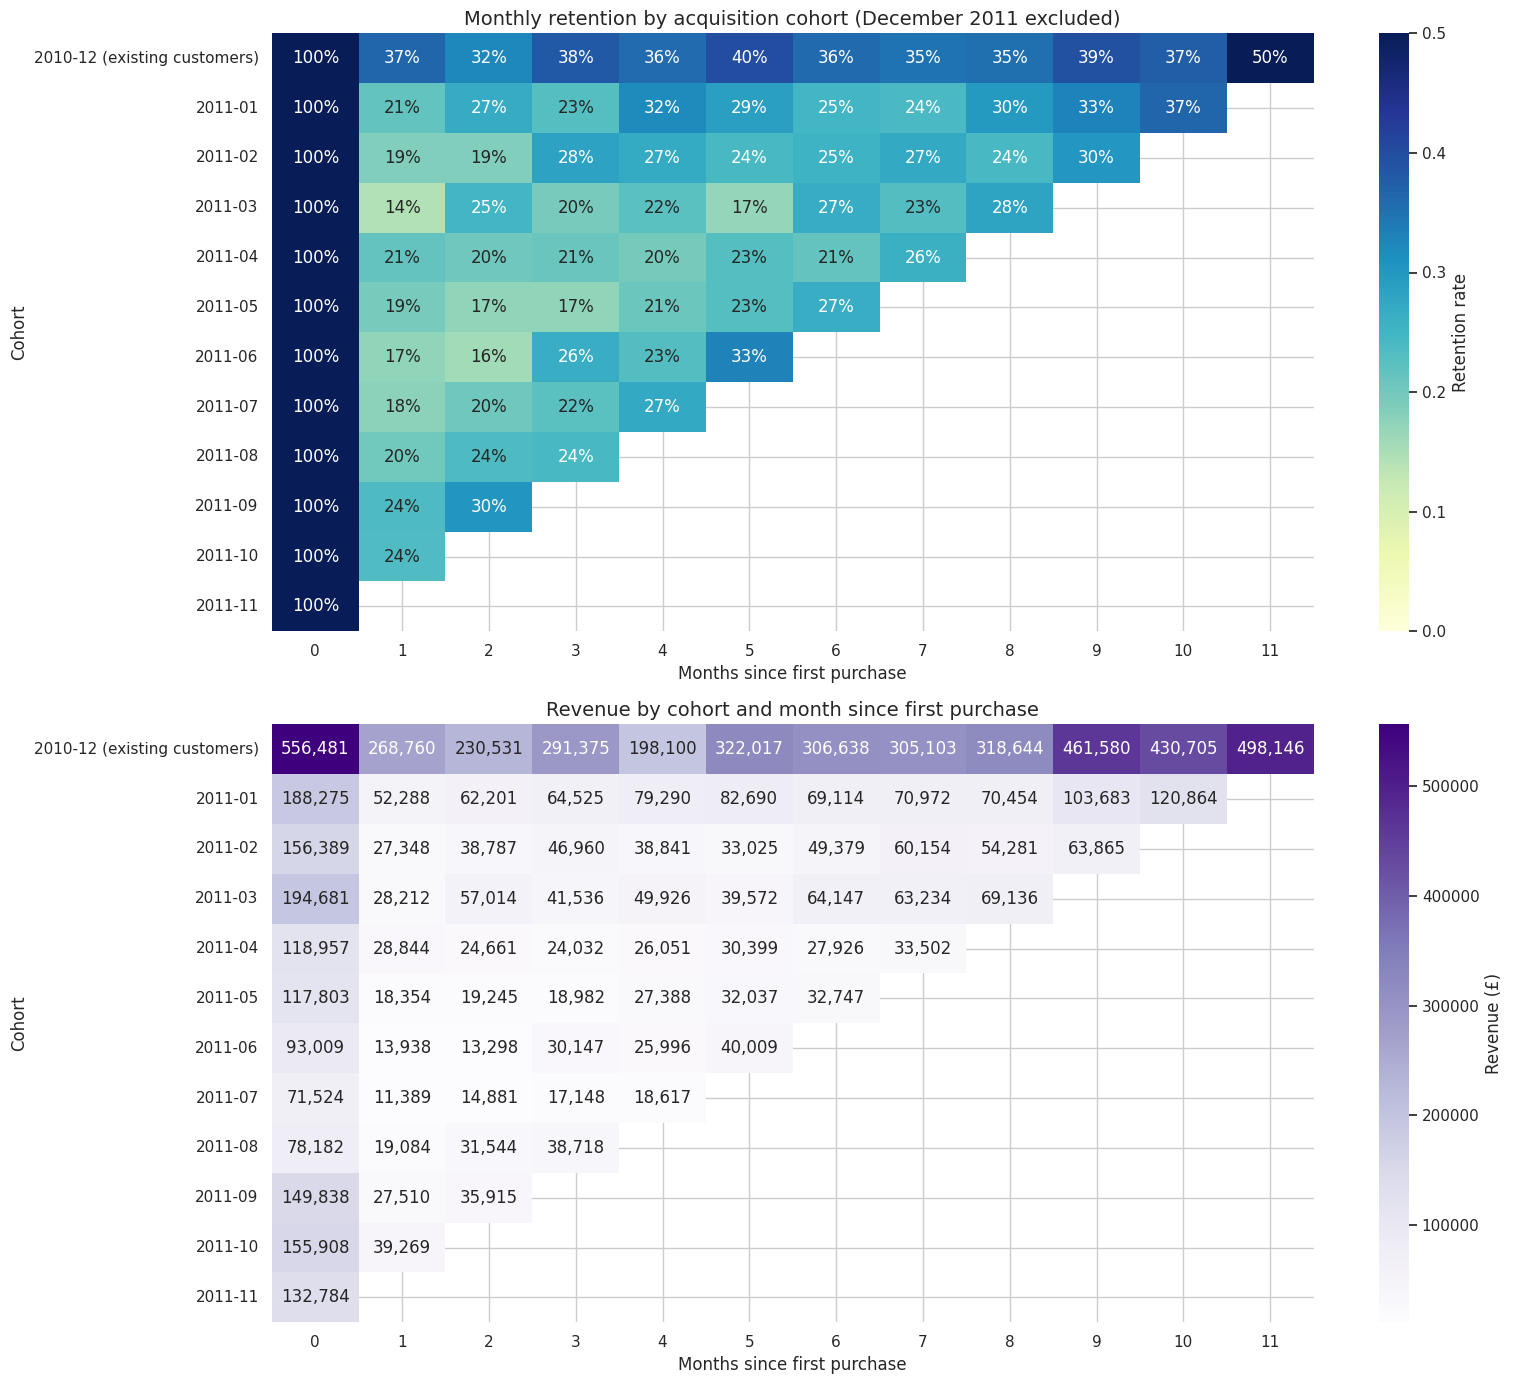

In [29]:
LAST_FULL = pd.Period('2011-11', 'M')
d = df_cust[df_cust['InvoiceDate'] < '2011-12-01'][['CustomerID', 'InvoiceDate', 'TotalPrice']].copy()
d['CohortMonth'] = d.groupby('CustomerID')['InvoiceDate'].transform('min').dt.to_period('M')
d['TxMonth'] = d['InvoiceDate'].dt.to_period('M')
d['CohortIndex'] = (d['TxMonth'].dt.year - d['CohortMonth'].dt.year) * 12 + (d['TxMonth'].dt.month - d['CohortMonth'].dt.month)

users = d.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().unstack()
revenue = d.groupby(['CohortMonth', 'CohortIndex'])['TotalPrice'].sum().unstack()

# Months that each cohort could actually be observed; zero-activity months inside the window are 0, months beyond it are NaN
max_idx = pd.Series([(LAST_FULL.year - p.year) * 12 + (LAST_FULL.month - p.month) for p in users.index], index=users.index)
cols = range(int(max_idx.max()) + 1)
users, revenue = users.reindex(columns=cols), revenue.reindex(columns=cols)
for c in users.index:
    obs = [k for k in cols if k <= max_idx[c]]
    users.loc[c, obs] = users.loc[c, obs].fillna(0)
    revenue.loc[c, obs] = revenue.loc[c, obs].fillna(0)

EXISTING = '2010-12 (existing customers)'
labels = {p: (EXISTING if p == pd.Period('2010-12', 'M') else str(p)) for p in users.index}
users.index = users.index.map(labels); revenue.index = revenue.index.map(labels)
retention = users.div(users[0], axis=0)

fig, axes = plt.subplots(2, 1, figsize=(16, 14))
sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=0.5, ax=axes[0], cbar_kws={'label': 'Retention rate'})
axes[0].set_title('Monthly retention by acquisition cohort (December 2011 excluded)'); axes[0].set_xlabel('Months since first purchase'); axes[0].set_ylabel('Cohort')
sns.heatmap(revenue, annot=True, fmt=',.0f', cmap='Purples', ax=axes[1], cbar_kws={'label': 'Revenue (£)'})
axes[1].set_title('Revenue by cohort and month since first purchase'); axes[1].set_xlabel('Months since first purchase'); axes[1].set_ylabel('Cohort')
plt.tight_layout(); plt.show()

retention.to_csv(f'{OUT_DIR}/cohort_retention_matrix.csv'); revenue.to_csv(f'{OUT_DIR}/cohort_revenue_matrix.csv')

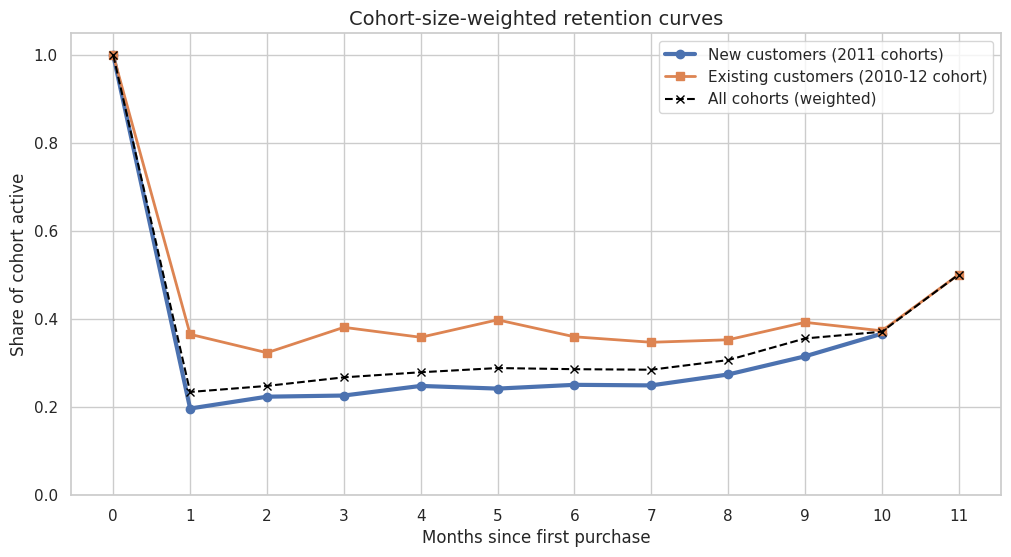

Insight: only 20% of new customers order again in the month after their first purchase (cohort range 14%-24%, best: 2011-09); by month 3 it is 23% and by month 6 25%.
The existing-customer cohort stays more active: 37% in month 1, 36% in month 6. This reflects loyal pre-existing buyers, not acquisition quality.
After the first month, the share of a cohort active in any given month stays within a narrow 20%-25% band through month 6 (later months rest on only a few early cohorts and are noisier), so the largest loss is between the first purchase and the next month.


In [30]:
# Cohort-size-weighted retention curves: all cohorts, existing customers (2010-12) and genuinely new customers (2011 cohorts)
def weighted_curve(u):
    num = u.sum()
    den = u.notna().mul(u[0], axis=0).sum()
    return (num / den)

is_existing = users.index == EXISTING
curve_all, curve_exist, curve_new = weighted_curve(users), weighted_curve(users[is_existing]), weighted_curve(users[~is_existing])

plt.figure(figsize=(12, 6))
plt.plot(curve_new.index, curve_new.values, marker='o', linewidth=3, label='New customers (2011 cohorts)')
plt.plot(curve_exist.index, curve_exist.values, marker='s', linewidth=2, label='Existing customers (2010-12 cohort)')
plt.plot(curve_all.index, curve_all.values, marker='x', linestyle='--', color='black', label='All cohorts (weighted)')
plt.title('Cohort-size-weighted retention curves'); plt.xlabel('Months since first purchase'); plt.ylabel('Share of cohort active')
plt.xticks(list(cols)); plt.ylim(0, 1.05); plt.legend(); plt.show()

new_rows = users[~is_existing]
m1 = (new_rows[1] / new_rows[0]).dropna()
print(f"Insight: only {curve_new[1]*100:.0f}% of new customers order again in the month after their first purchase "
      f"(cohort range {m1.min()*100:.0f}%-{m1.max()*100:.0f}%, best: {m1.idxmax()}); by month 3 it is {curve_new[3]*100:.0f}% and by month 6 {curve_new[6]*100:.0f}%.")
print(f"The existing-customer cohort stays more active: {curve_exist[1]*100:.0f}% in month 1, {curve_exist[6]*100:.0f}% in month 6. "
      f"This reflects loyal pre-existing buyers, not acquisition quality.")
band = curve_new.loc[1:6]
print(f"After the first month, the share of a cohort active in any given month stays within a narrow {band.min()*100:.0f}%-{band.max()*100:.0f}% band through month 6 "
      f"(later months rest on only a few early cohorts and are noisier), so the largest loss is between the first purchase and the next month.")

### Cohort takeaways
- The sharpest loss happens between the first and second month; after that, the share of customers still ordering is comparatively stable.
- The December 2010 cohort cannot be treated as a "best acquisition month": it mostly contains customers who were already active.
- Because retention is measured for any purchase in a month, it is a conservative measure for a business whose customers often buy every few months.
- A segment-versus-retention comparison was deliberately **not** included: segments are defined from the same purchase history (recent frequent buyers are "Champions" by construction), so such a chart would be circular.

## Step 9: Customer lifetime value (CLV)
We use the **BG/NBD** model (expected number of future purchases and probability the customer is still "alive") and the **Gamma-Gamma** model (expected spend per order).

Modelling choices:
- BG/NBD is fitted on **all** customers, including one-time buyers; excluding them would overstate purchase rates and survival.
- Gamma-Gamma is fitted on **repeat** customers only (it needs at least two purchases). One-time buyers use their own order value.
- CLV here is the **expected revenue over the next 90 days** = expected purchases × expected order value. It is revenue, not profit (there is no cost data).

In [31]:
!pip install -q lifetimes mlxtend

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584.2/584.2 kB 10.5 MB/s eta 0:00:00


In [32]:
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data, calibration_and_holdout_data
from lifetimes.plotting import plot_calibration_purchases_vs_holdout_purchases

obs_end = df_cust['InvoiceDate'].max()
clv_summary = summary_data_from_transaction_data(df_cust, customer_id_col='CustomerID', datetime_col='InvoiceDate',
                                                 monetary_value_col='TotalPrice', observation_period_end=obs_end)
print(f"Customers: {len(clv_summary):,} (one-time buyers: {(clv_summary['frequency'] == 0).sum():,}, repeat buyers: {(clv_summary['frequency'] > 0).sum():,})")
display(clv_summary.head())

# BG/NBD on ALL customers - increased penalizer_coef to 0.1 to fix convergence issues
bgf = BetaGeoFitter(penalizer_coef=0.1)
bgf.fit(clv_summary['frequency'], clv_summary['recency'], clv_summary['T'])
print("\nBG/NBD parameters:", {k: round(float(v), 3) for k, v in bgf.params_.items()})

# Gamma-Gamma on repeat customers only
repeaters = clv_summary[(clv_summary['frequency'] > 0) & (clv_summary['monetary_value'] > 0)]
print(f"\nCorrelation between frequency and monetary value among repeaters (Gamma-Gamma assumes ~0): "
      f"{repeaters[['frequency', 'monetary_value']].corr().iloc[0, 1]:.2f}")
ggf = GammaGammaFitter(penalizer_coef=0.1)
ggf.fit(repeaters['frequency'], repeaters['monetary_value'])
print("Gamma-Gamma parameters:", {k: round(float(v), 3) for k, v in ggf.params_.items()})

Customers: 4,324 (one-time buyers: 1,555, repeat buyers: 2,769)


,frequency,recency,T,monetary_value
CustomerID,,,,
12347,6.00,365.00,367.00,599.70
12348,3.00,283.00,358.00,261.48
12349,0.00,0.00,18.00,0.00
12350,0.00,0.00,310.00,0.00
12352,5.00,260.00,296.00,193.78



BG/NBD parameters: {'r': 0.591, 'alpha': 49.728, 'a': 0.0, 'b': 0.0}

Correlation between frequency and monetary value among repeaters (Gamma-Gamma assumes ~0): 0.13
Gamma-Gamma parameters: {'p': 1.033, 'q': 0.179, 'v': 0.931}


In [33]:
HORIZON = 90
clv = clv_summary.copy()
clv['p_alive'] = bgf.conditional_probability_alive(clv['frequency'], clv['recency'], clv['T'])
clv['predicted_purchases_90'] = bgf.conditional_expected_number_of_purchases_up_to_time(HORIZON, clv['frequency'], clv['recency'], clv['T'])

# Expected order value: Gamma-Gamma for repeaters, the customer's own average order value for one-time buyers
own_aov = (rfm.set_index('CustomerID')['Monetary'] / rfm.set_index('CustomerID')['Frequency']).reindex(clv.index)
clv['expected_order_value'] = own_aov
rep_mask = (clv['frequency'] > 0) & (clv['monetary_value'] > 0)
clv.loc[rep_mask, 'expected_order_value'] = ggf.conditional_expected_average_profit(clv.loc[rep_mask, 'frequency'], clv.loc[rep_mask, 'monetary_value'])
clv['predicted_clv_90'] = clv['predicted_purchases_90'] * clv['expected_order_value']
clv['Segment'] = rfm.set_index('CustomerID')['Segment'].reindex(clv.index)

print("Predicted 90-day CLV summary (£):")
display(clv[['p_alive', 'predicted_purchases_90', 'expected_order_value', 'predicted_clv_90']].describe())
print(f"Total expected revenue from identified customers over the next {HORIZON} days: £{clv['predicted_clv_90'].sum():,.0f}")
print(f"Top 10% of customers account for {clv['predicted_clv_90'].nlargest(int(len(clv)*0.1)).sum() / clv['predicted_clv_90'].sum()*100:.0f}% of expected 90-day revenue.")
clv.reset_index().to_csv(f'{OUT_DIR}/clv.csv', index=False)

Predicted 90-day CLV summary (£):


,p_alive,predicted_purchases_90,expected_order_value,predicted_clv_90
count,4324.00,4305.00,4324.00,4305.00
mean,1.00,1.06,734.11,758.96
std,0.00,1.34,1929.70,2155.02
min,1.00,0.13,2.90,0.58
25%,1.00,0.39,228.98,117.22
50%,1.00,0.71,399.00,353.62
75%,1.00,1.28,752.12,794.11
max,1.00,27.16,104996.78,64118.64


Total expected revenue from identified customers over the next 90 days: £3,267,311
Top 10% of customers account for 51% of expected 90-day revenue.


Holdout customers: 3,364
Total purchases  actual: 4,445 | predicted: 3,259 (-26.7%)
Per-customer MAE   model: 0.925 | flat-average benchmark: 1.314
Per-customer RMSE  model: 1.499 | flat-average benchmark: 2.250


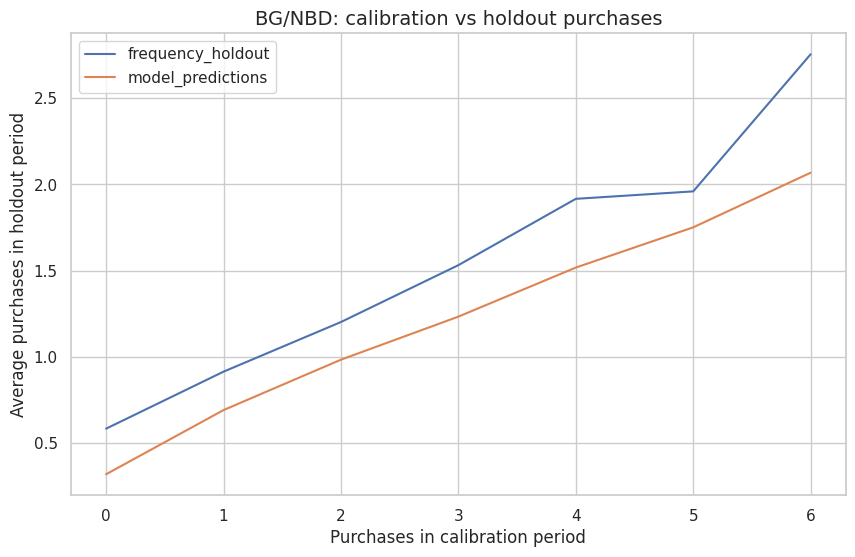

In [34]:
# Validation: fit on a calibration period, predict the last 90 days, compare with what really happened
cal_end = obs_end - pd.Timedelta(days=HORIZON)
cal_hold = calibration_and_holdout_data(df_cust, customer_id_col='CustomerID', datetime_col='InvoiceDate',
                                        calibration_period_end=cal_end, observation_period_end=obs_end, monetary_value_col='TotalPrice')

# Fixed the error by increasing the penalizer_coef to 0.1 to stabilize parameter optimization
bgf_cal = BetaGeoFitter(penalizer_coef=0.1)
bgf_cal.fit(cal_hold['frequency_cal'], cal_hold['recency_cal'], cal_hold['T_cal'])
cal_hold['pred_holdout'] = bgf_cal.conditional_expected_number_of_purchases_up_to_time(
    cal_hold['duration_holdout'], cal_hold['frequency_cal'], cal_hold['recency_cal'], cal_hold['T_cal'])

actual, pred = cal_hold['frequency_holdout'], cal_hold['pred_holdout']
naive = pd.Series(actual.mean(), index=actual.index)    # no-model benchmark: everyone gets the average
print(f"Holdout customers: {len(cal_hold):,}")
print(f"Total purchases  actual: {actual.sum():,.0f} | predicted: {pred.sum():,.0f} ({(pred.sum()/actual.sum()-1)*100:+.1f}%)")
print(f"Per-customer MAE   model: {mean_absolute_error(actual, pred):.3f} | flat-average benchmark: {mean_absolute_error(actual, naive):.3f}")
print(f"Per-customer RMSE  model: {np.sqrt(mean_squared_error(actual, pred)):.3f} | flat-average benchmark: {np.sqrt(mean_squared_error(actual, naive)):.3f}")

ax = plot_calibration_purchases_vs_holdout_purchases(bgf_cal, cal_hold)
ax.set_title('BG/NBD: calibration vs holdout purchases'); ax.set_xlabel('Purchases in calibration period'); ax.set_ylabel('Average purchases in holdout period')
plt.show()

Top 20 customers by predicted 90-day CLV:


,frequency,monetary_value,p_alive,predicted_purchases_90,expected_order_value,predicted_clv_90,Segment
CustomerID,,,,,,,
14646,44.00,6333.77,1.00,9.94,6450.32,64118.64,Champions
18102,25.00,9349.48,1.00,5.53,9656.55,53370.64,Champions
17450,26.00,7214.57,1.00,5.74,7442.12,42739.04,Champions
15749,1.00,21535.90,1.00,0.38,104996.78,39390.63,At Risk
14096,16.00,3327.99,1.00,9.91,3502.02,34693.29,Champions
12415,13.00,8984.27,1.00,3.16,9569.46,30267.92,Loyal Customers
14911,127.00,1016.92,1.00,27.16,1023.34,27798.41,Champions
14156,42.00,2703.43,1.00,9.11,2755.60,25106.02,Champions
13868,1.00,2685.00,1.00,1.63,13094.50,21375.75,Potential Loyalists


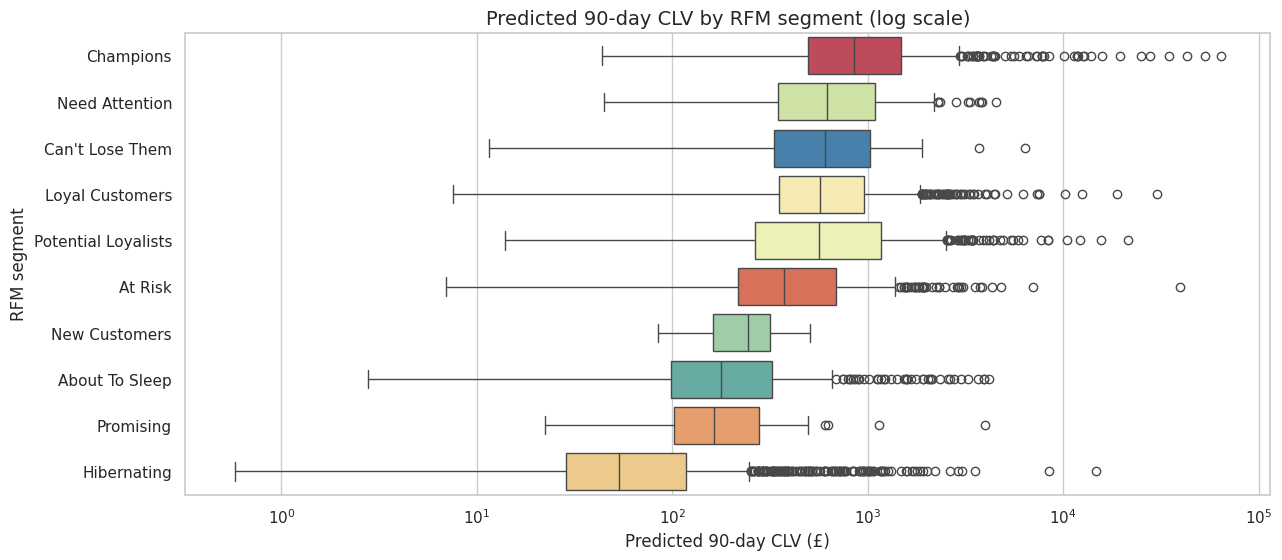

Insight: Champions account for 34% of expected 90-day revenue; 12 of the top 20 customers are Champions.


In [35]:
top20 = clv.sort_values('predicted_clv_90', ascending=False).head(20)
print("Top 20 customers by predicted 90-day CLV:")
display(top20[['frequency', 'monetary_value', 'p_alive', 'predicted_purchases_90', 'expected_order_value', 'predicted_clv_90', 'Segment']])

plt.figure(figsize=(14, 6))
order_seg = clv.groupby('Segment')['predicted_clv_90'].median().sort_values(ascending=False).index
sns.boxplot(data=clv, x='predicted_clv_90', y='Segment', order=order_seg, hue='Segment', palette='Spectral', legend=False)
plt.xscale('log'); plt.title('Predicted 90-day CLV by RFM segment (log scale)'); plt.xlabel('Predicted 90-day CLV (£)'); plt.ylabel('RFM segment')
plt.show()
seg_clv = clv.groupby('Segment')['predicted_clv_90'].sum().sort_values(ascending=False)
print(f"Insight: {seg_clv.index[0]} account for {seg_clv.iloc[0]/seg_clv.sum()*100:.0f}% of expected 90-day revenue; "
      f"{(top20['Segment'] == 'Champions').sum()} of the top 20 customers are Champions.")

## Step 10: Market basket analysis (association rules)
UK invoices only (the dominant market). To keep the analysis memory-friendly we use the 150 products that appear on the most invoices, and only invoices with at least two of those products. FP-Growth finds frequent item combinations; we keep one-to-one rules with **lift > 1.2** and **confidence > 0.5**, and show each product pair once (in the direction with the higher confidence).

In [48]:
from mlxtend.frequent_patterns import fpgrowth, association_rules
import networkx as nx

df_uk = df_all[df_all['Country'] == 'United Kingdom']
top_items = df_uk.groupby('Description')['InvoiceNo'].nunique().nlargest(150).index
basket = (df_uk[df_uk['Description'].isin(top_items)]
          .groupby(['InvoiceNo', 'Description'])['Quantity'].sum().unstack(fill_value=0)) > 0
basket = basket[basket.sum(axis=1) >= 2]
print(f"Basket matrix: {basket.shape[0]:,} invoices x {basket.shape[1]} products")

frequent = fpgrowth(basket, min_support=0.02, use_colnames=True)
try:
    rules = association_rules(frequent, metric='lift', min_threshold=1.2)
except TypeError:                                   # newer mlxtend versions require num_itemsets
    rules = association_rules(frequent, num_itemsets=len(basket), metric='lift', min_threshold=1.2)
rules = rules[rules['confidence'] > 0.5].copy()
print(f"Frequent itemsets: {len(frequent):,} | rules with lift > 1.2 and confidence > 0.5: {len(rules):,}")

pairs = rules[(rules['antecedents'].apply(len) == 1) & (rules['consequents'].apply(len) == 1)].copy()
pairs['Antecedent'] = pairs['antecedents'].apply(lambda s: next(iter(s)))
pairs['Consequent'] = pairs['consequents'].apply(lambda s: next(iter(s)))
pairs['pair'] = pairs.apply(lambda r: tuple(sorted([r['Antecedent'], r['Consequent']])), axis=1)
pairs = pairs.sort_values('confidence', ascending=False).drop_duplicates('pair').sort_values('lift', ascending=False)
print(f"One-to-one rules (each product pair shown once): {len(pairs):,}")

top15 = pairs.head(15)
display(top15[['Antecedent', 'Consequent', 'support', 'confidence', 'lift']])

Basket matrix: 12,735 invoices x 150 products
Frequent itemsets: 474 | rules with lift > 1.2 and confidence > 0.5: 251
One-to-one rules (each product pair shown once): 76


,Antecedent,Consequent,support,confidence,lift
256,HAND WARMER SCOTTY DOG DESIGN,HAND WARMER OWL DESIGN,0.03,0.62,12.86
258,HAND WARMER SCOTTY DOG DESIGN,HAND WARMER BIRD DESIGN,0.02,0.53,12.79
409,BLUE HARMONICA IN BOX,RED HARMONICA IN BOX,0.02,0.53,12.71
261,HAND WARMER BIRD DESIGN,HAND WARMER OWL DESIGN,0.02,0.56,11.69
665,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.04,0.83,11.44
881,LARGE WHITE HEART OF WICKER,SMALL WHITE HEART OF WICKER,0.02,0.54,11.36
434,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.03,0.61,11.14
669,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.04,0.79,10.63
126,STRAWBERRY CHARLOTTE BAG,WOODLAND CHARLOTTE BAG,0.03,0.56,10.52
878,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.04,0.73,10.43


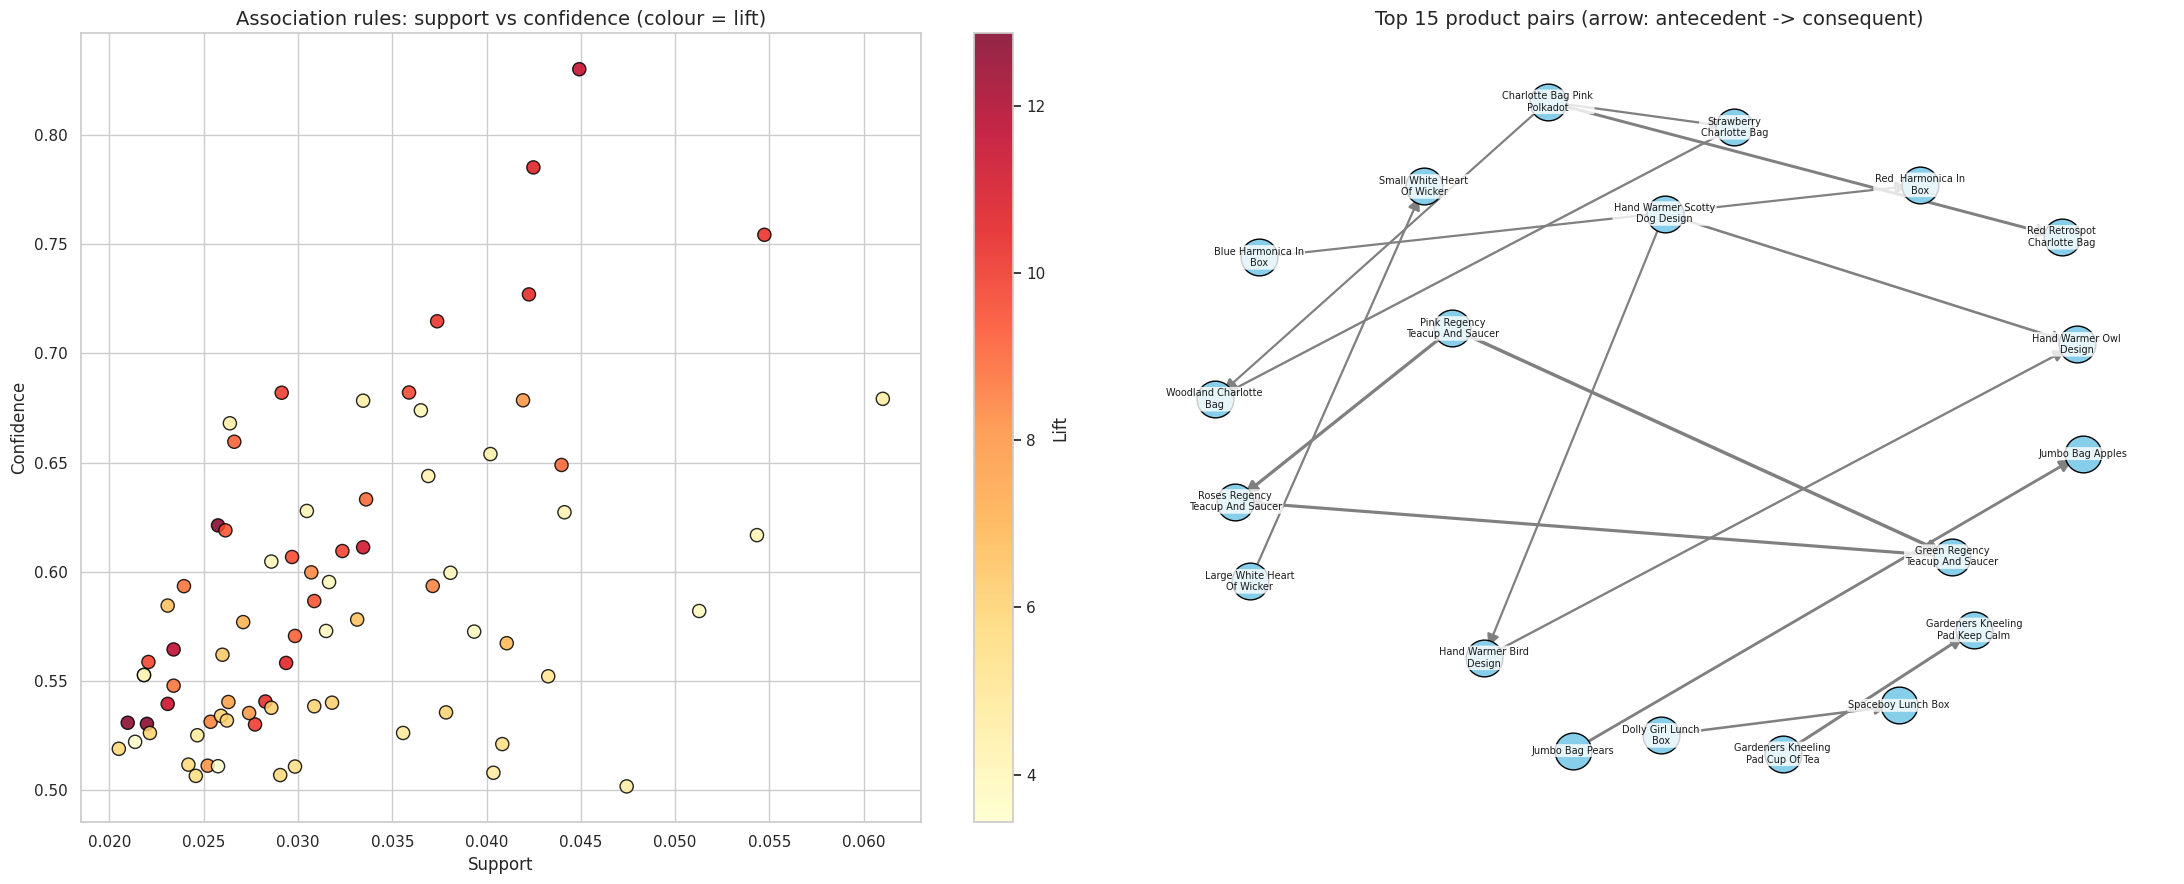

Frequently bought together (top 5 pairs):
  - Hand Warmer Scotty Dog Design -> Hand Warmer Owl Design: lift 12.9, confidence 62%, support 2.6%
  - Hand Warmer Scotty Dog Design -> Hand Warmer Bird Design: lift 12.8, confidence 53%, support 2.2%
  - Blue Harmonica In Box -> Red  Harmonica In Box: lift 12.7, confidence 53%, support 2.1%
  - Hand Warmer Bird Design -> Hand Warmer Owl Design: lift 11.7, confidence 56%, support 2.3%
  - Pink Regency Teacup And Saucer -> Green Regency Teacup And Saucer: lift 11.4, confidence 83%, support 4.5%


In [49]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sc = axes[0].scatter(pairs['support'], pairs['confidence'], c=pairs['lift'], cmap='YlOrRd', s=90, edgecolors='black', alpha=0.85)
fig.colorbar(sc, ax=axes[0], label='Lift')
axes[0].set_title('Association rules: support vs confidence (colour = lift)'); axes[0].set_xlabel('Support'); axes[0].set_ylabel('Confidence')

G = nx.DiGraph()
for _, r in top15.iterrows():
    G.add_edge(r['Antecedent'], r['Consequent'], weight=r['confidence'])
pos = nx.spring_layout(G, k=1.4, seed=SEED)
nx.draw_networkx_nodes(G, pos, ax=axes[1], node_color='skyblue', node_size=700, edgecolors='black')
nx.draw_networkx_edges(G, pos, ax=axes[1], width=[G[u][v]['weight'] * 3 for u, v in G.edges()], edge_color='gray', arrows=True, arrowsize=18)
nx.draw_networkx_labels(G, pos, labels={n: textwrap.fill(n.title(), 18) for n in G.nodes()}, font_size=7, ax=axes[1],
                        bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))
axes[1].set_title('Top 15 product pairs (arrow: antecedent -> consequent)'); axes[1].axis('off')
plt.tight_layout(); plt.show()

pairs.drop(columns=['pair']).assign(antecedents=lambda x: x['Antecedent'], consequents=lambda x: x['Consequent']).drop(columns=['Antecedent', 'Consequent']).to_csv(f'{OUT_DIR}/association_rules.csv', index=False)

print("Frequently bought together (top 5 pairs):")
for _, r in pairs.head(5).iterrows():
    print(f"  - {r['Antecedent'].title()} -> {r['Consequent'].title()}: lift {r['lift']:.1f}, confidence {r['confidence']*100:.0f}%, support {r['support']*100:.1f}%")

### Business use of the rules
- **Bundling:** offer high-lift pairs as a package at a modest discount instead of discounting items separately.
- **Cross-selling:** when a customer adds an antecedent item to the basket, recommend its consequent ("frequently bought together").
- **Merchandising and warehouse layout:** place strongly associated items next to each other on category pages and in pick locations.
- **Read the pairs as product families.** Rules are mostly colour or design variants of the same range, which suggests customers tend to buy a whole range rather than a single item.
- Lift measures association, not causation; promotions should be A/B tested.

## Step 11: Weekly revenue forecasting
Design choices, based on what the data actually contains:
- **Only complete Monday–Sunday weeks** are used: the first partial week (data starts on a Wednesday) and the last partial week (data ends on 9 Dec 2011) are dropped.
- **Christmas closure.** The retailer shut down between Christmas and New Year, so one week has zero revenue. This is a business closure, not demand, so for model fitting these weeks are replaced by interpolation, and the closure pattern from last year is re-applied to the forecast weeks afterwards.
- **No seasonal model.** One year of data cannot estimate annual seasonality, and an arbitrary short seasonal period (such as 12 weeks) has no business justification.
- Models are compared on a **chronological hold-out (last 8 weeks)** against simple baselines. A model has to beat the baselines to be worth using.

Complete weeks: 52 (12 Dec 2010 to 04 Dec 2011); dropped 2 partial weeks.
Weeks below 50% of the median weekly revenue (holiday closures and slow weeks):
InvoiceDate
2011-01-02       0.00
2011-05-01   81531.00


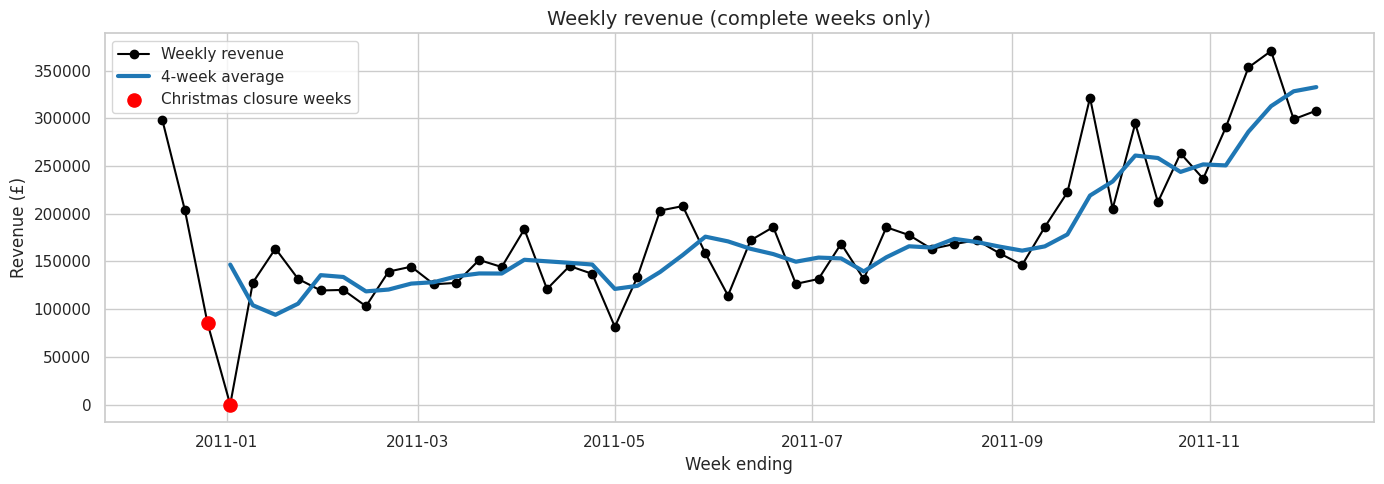

Insight: average weekly revenue rises from £141,301 in the first half of the year to £291,768 in the last 8 weeks, with a shutdown dip of £0 to £85,100 over Christmas.


In [50]:
daily = df_all.groupby(df_all['InvoiceDate'].dt.normalize())['TotalPrice'].sum()
weekly_all = daily.resample('W-SUN').sum()                       # weeks run Monday..Sunday and are labelled by their Sunday

data_start, data_end = df_all['InvoiceDate'].min().normalize(), df_all['InvoiceDate'].max().normalize()
is_complete = ((weekly_all.index - pd.Timedelta(days=6)) >= data_start) & (weekly_all.index <= data_end)
weekly = weekly_all[is_complete].asfreq('W-SUN')
print(f"Complete weeks: {len(weekly)} ({weekly.index[0]:%d %b %Y} to {weekly.index[-1]:%d %b %Y}); dropped {len(weekly_all) - len(weekly)} partial weeks.")

low = weekly[weekly < 0.5 * weekly.median()]
print("Weeks below 50% of the median weekly revenue (holiday closures and slow weeks):")
print(low.round(0).to_string())

# Closure weeks of last year (business shut from Christmas to New Year); replaced by interpolation for model fitting only
CLOSURE_LY = pd.to_datetime(['2010-12-26', '2011-01-02'])
weekly_model = weekly.copy()
weekly_model.loc[CLOSURE_LY] = np.nan
weekly_model = weekly_model.interpolate(limit_direction='both')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weekly.index, weekly.values, marker='o', color='black', label='Weekly revenue')
ax.plot(weekly.index, weekly.rolling(4).mean(), color='tab:blue', linewidth=3, label='4-week average')
ax.scatter(CLOSURE_LY, weekly.loc[CLOSURE_LY], color='red', zorder=5, s=90, label='Christmas closure weeks')
ax.set_title('Weekly revenue (complete weeks only)'); ax.set_xlabel('Week ending'); ax.set_ylabel('Revenue (£)'); ax.legend()
plt.tight_layout(); plt.show()
print(f"Insight: average weekly revenue rises from £{weekly.iloc[:26].mean():,.0f} in the first half of the year to £{weekly.iloc[-8:].mean():,.0f} in the last 8 weeks, "
      f"with a shutdown dip of £{weekly.loc[CLOSURE_LY].min():,.0f} to £{weekly.loc[CLOSURE_LY].max():,.0f} over Christmas.")

In [51]:
# Baselines on the last-8-weeks hold-out
H = 8
train, test = weekly_model.iloc[:-H], weekly.iloc[-H:]
def metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return {'MAE': np.mean(np.abs(actual - pred)), 'RMSE': np.sqrt(np.mean((actual - pred) ** 2)),
            'MAPE %': np.mean(np.abs((actual - pred) / actual)) * 100}
base_preds = {'Naive (last week)': np.repeat(train.iloc[-1], H), '4-week moving average': np.repeat(train.iloc[-4:].mean(), H)}
print(f"Train: {len(train)} weeks | Test: {len(test)} weeks ({test.index[0]:%d %b} to {test.index[-1]:%d %b %Y})")
display(pd.DataFrame({k: metrics(test, v) for k, v in base_preds.items()}).T)

Train: 44 weeks | Test: 8 weeks (16 Oct to 04 Dec 2011)


,MAE,RMSE,MAPE %
Naive (last week),41053.65,50718.37,14.96
4-week moving average,48986.15,59204.44,16.00


ADF test on weekly revenue: statistic 1.57, p-value 0.998 -> not stationary (differencing / trend handling needed)


,MAE,RMSE,MAPE %,Sane
Naive (last week),41053.65,50718.37,14.96,True
4-week moving average,48986.15,59204.44,16.00,True
ETS (damped trend),50757.95,61162.94,16.37,True
"ARIMA(1,1,1)",60478.71,72549.06,19.31,True


Best hold-out model: Naive (last week) (MAPE 15.0%)


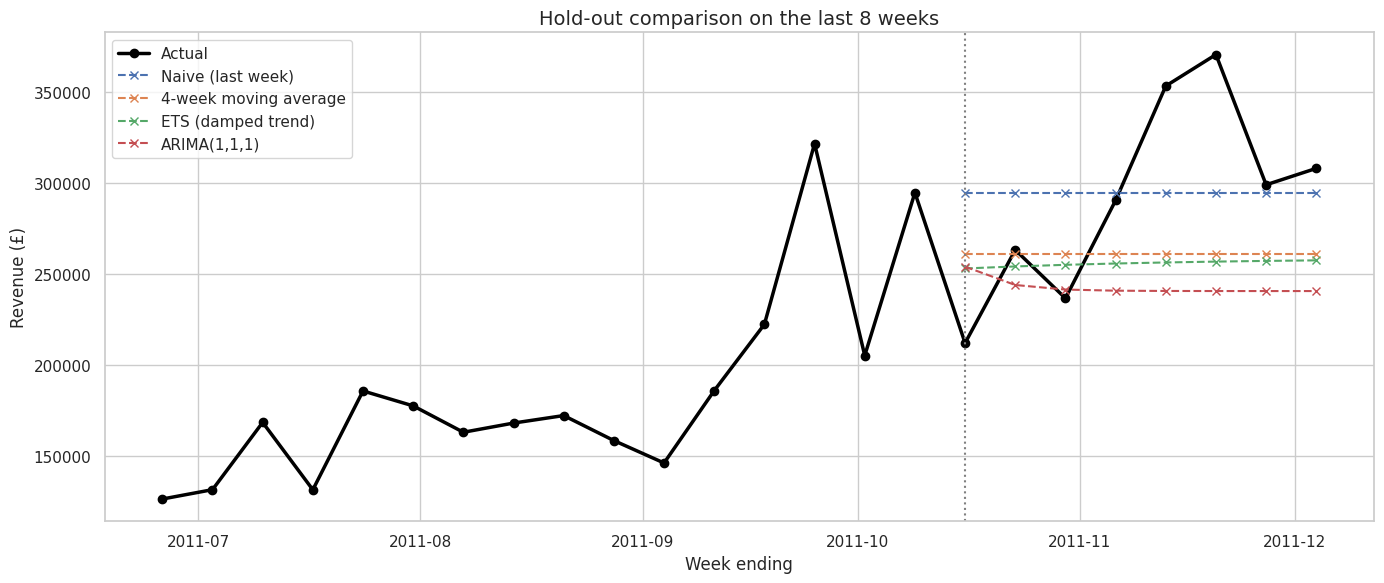

In [52]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

adf_stat, adf_p = adfuller(weekly_model)[:2]
print(f"ADF test on weekly revenue: statistic {adf_stat:.2f}, p-value {adf_p:.3f} -> "
      f"{'stationary' if adf_p < 0.05 else 'not stationary (differencing / trend handling needed)'}")

preds = dict(base_preds)
preds['ETS (damped trend)'] = np.asarray(ExponentialSmoothing(train, trend='add', damped_trend=True).fit().forecast(H))
preds['ARIMA(1,1,1)'] = np.asarray(ARIMA(train, order=(1, 1, 1)).fit().forecast(H))

def is_sane(p):                                   # guard against numerically unstable fits
    return bool(np.all(np.isfinite(p)) and np.all(p >= 0) and np.max(p) <= 3 * train.max())

results = pd.DataFrame({k: {**metrics(test, v), 'Sane': is_sane(v)} for k, v in preds.items()}).T
results[['MAE', 'RMSE', 'MAPE %']] = results[['MAE', 'RMSE', 'MAPE %']].astype(float)
display(results)
eligible = results[results['Sane']]
best_model = eligible['MAPE %'].idxmin()
print(f"Best hold-out model: {best_model} (MAPE {results.loc[best_model, 'MAPE %']:.1f}%)")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(weekly.index[-24:], weekly.iloc[-24:], marker='o', color='black', linewidth=2.5, label='Actual')
for name, p in preds.items():
    ax.plot(test.index, p, marker='x', linestyle='--', label=name)
ax.axvline(test.index[0], color='grey', linestyle=':')
ax.set_title('Hold-out comparison on the last 8 weeks'); ax.set_xlabel('Week ending'); ax.set_ylabel('Revenue (£)'); ax.legend()
plt.tight_layout(); plt.show()

,week_ending,model_forecast,holiday_ratio,forecast,lower_95,upper_95
0,2011-12-11,308134.57,1.00,308134.57,208726.56,407542.58
1,2011-12-18,308134.57,1.00,308134.57,208726.56,407542.58
2,2011-12-25,308134.57,0.34,104466.73,70764.48,138168.98
3,2012-01-01,308134.57,0.00,0.00,0.00,0.00
4,2012-01-08,308134.57,1.00,308134.57,208726.56,407542.58
5,2012-01-15,308134.57,1.00,308134.57,208726.56,407542.58
6,2012-01-22,308134.57,1.00,308134.57,208726.56,407542.58
7,2012-01-29,308134.57,1.00,308134.57,208726.56,407542.58


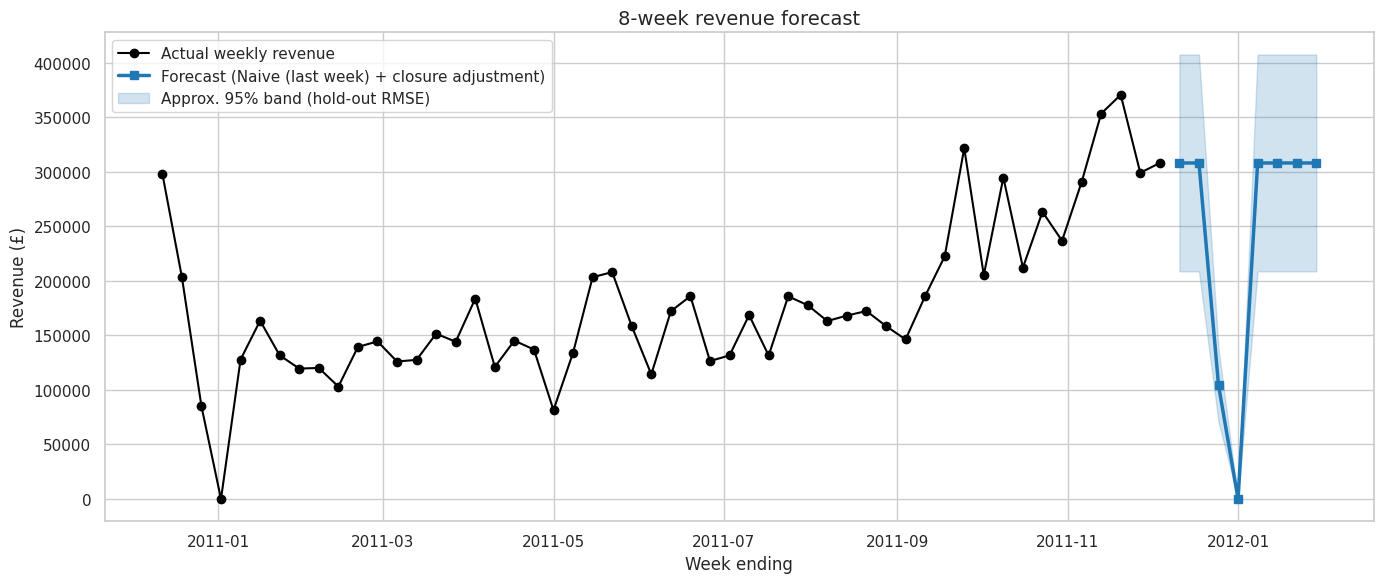

Insight: the forecast applies last year's closure pattern to 2 weeks (ratios 0.34, 0.00), giving a closure-week forecast of £0-£104,467 instead of roughly £308,135 in a normal week.


In [53]:
# Final forecast: refit the best model on all complete weeks, then re-apply last year's Christmas closure pattern
def fit_forecast(name, series, h):
    if name == 'Naive (last week)':      return np.repeat(series.iloc[-1], h)
    if name == '4-week moving average':  return np.repeat(series.iloc[-4:].mean(), h)
    if name == 'ETS (damped trend)':     return np.asarray(ExponentialSmoothing(series, trend='add', damped_trend=True).fit().forecast(h))
    return np.asarray(ARIMA(series, order=(1, 1, 1)).fit().forecast(h))

raw = fit_forecast(best_model, weekly_model, H)
assert is_sane(raw), "Final forecast failed the sanity check"
future_index = pd.date_range(weekly.index[-1] + pd.Timedelta(weeks=1), periods=H, freq='W-SUN')

# Closure ratio = last year's closure-week revenue relative to the two preceding normal weeks
ref = weekly.loc[['2010-12-12', '2010-12-19']].mean()
ratio = pd.Series(1.0, index=future_index)
for fdate in future_index:
    analog = fdate - pd.Timedelta(days=364)
    if analog in CLOSURE_LY:
        ratio[fdate] = weekly.loc[analog] / ref
adjusted = raw * ratio.values
rmse = results.loc[best_model, 'RMSE']
forecast_df = pd.DataFrame({'week_ending': future_index, 'model_forecast': raw, 'holiday_ratio': ratio.values, 'forecast': adjusted,
                            'lower_95': np.clip(adjusted - 1.96 * rmse * ratio.values, 0, None), 'upper_95': adjusted + 1.96 * rmse * ratio.values})
assert (forecast_df[['forecast', 'lower_95', 'upper_95']] >= 0).all().all(), "Negative forecast values"
display(forecast_df)
forecast_df.to_csv(f'{OUT_DIR}/forecast.csv', index=False)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(weekly.index, weekly.values, marker='o', color='black', label='Actual weekly revenue')
ax.plot(forecast_df['week_ending'], forecast_df['forecast'], marker='s', color='tab:blue', linewidth=2.5, label=f'Forecast ({best_model} + closure adjustment)')
ax.fill_between(forecast_df['week_ending'], forecast_df['lower_95'], forecast_df['upper_95'], alpha=0.2, color='tab:blue', label='Approx. 95% band (hold-out RMSE)')
ax.set_title('8-week revenue forecast'); ax.set_xlabel('Week ending'); ax.set_ylabel('Revenue (£)'); ax.legend()
plt.tight_layout(); plt.show()
closure_fc = forecast_df[forecast_df['holiday_ratio'] < 1]
print(f"Insight: the forecast applies last year's closure pattern to {len(closure_fc)} weeks "
      f"(ratios {', '.join(f'{r:.2f}' for r in closure_fc['holiday_ratio'])}), giving a closure-week forecast of "
      f"£{closure_fc['forecast'].min():,.0f}-£{closure_fc['forecast'].max():,.0f} instead of roughly £{raw.mean():,.0f} in a normal week.")

### Forecasting limitations
- With only one year of history, the model cannot learn annual seasonality; the Christmas pattern is carried over from the single year observed, and the uncertainty band is wide.
- The hold-out has only 8 points, and the 8 weeks include the strong autumn ramp-up, so error metrics are noisy.
- The approximate 95% band uses the hold-out RMSE rather than a model-based interval.
- Treat the forecast as a planning baseline, not a precise prediction.

## Step 12: Customer master table and dashboard
All customer-level results are merged into one table (RFM segment, K-Means cluster, predicted CLV and probability of being active), and exported together with small aggregate tables for the Streamlit app.

In [54]:
# Aggregate tables for the dashboard / Streamlit app
monthly.to_csv(f'{OUT_DIR}/monthly_revenue.csv', index=False)
country_rev.to_csv(f'{OUT_DIR}/country_revenue.csv', index=False)
product_level.nlargest(20, 'TotalRevenue')[['StockCode', 'Description', 'TotalRevenue', 'TotalQuantitySold']].to_csv(f'{OUT_DIR}/top_products.csv', index=False)
print("Saved monthly_revenue.csv, country_revenue.csv, top_products.csv")

Saved monthly_revenue.csv, country_revenue.csv, top_products.csv


In [55]:
master = (rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R', 'F', 'M', 'RFM_Score', 'Segment']]
          .merge(rfm_ml[['CustomerID', 'Cluster_Name']], on='CustomerID', how='left')
          .merge(clv.reset_index()[['CustomerID', 'p_alive', 'predicted_purchases_90', 'expected_order_value', 'predicted_clv_90']], on='CustomerID', how='left'))
master[['R', 'F', 'M']] = master[['R', 'F', 'M']].astype(int)
assert master['CustomerID'].is_unique and len(master) == len(rfm)
print("Missing values per column:"); print(master.isnull().sum().to_string())
display(master.head())
master.to_csv(f'{OUT_DIR}/customer_master.csv', index=False)
print("Saved", f'{OUT_DIR}/customer_master.csv', master.shape)

Missing values per column:
CustomerID                 0
Recency                    0
Frequency                  0
Monetary                   0
R                          0
F                          0
M                          0
RFM_Score                  0
Segment                    0
Cluster_Name               0
p_alive                    0
predicted_purchases_90    19
expected_order_value       0
predicted_clv_90          19


,CustomerID,Recency,Frequency,Monetary,R,F,M,RFM_Score,Segment,Cluster_Name,p_alive,predicted_purchases_90,expected_order_value,predicted_clv_90
0,12347,2,7,4310.00,5,5,5,555,Champions,High-Value VIPs,1.00,1.42,691.46,984.29
1,12348,75,4,1437.24,2,4,4,244,At Risk,Active Mid-Spenders,1.00,0.79,356.16,282.33
2,12349,19,1,1457.55,4,1,4,414,Promising,Active Mid-Spenders,1.00,0.79,1457.55,1145.10
3,12350,310,1,294.40,1,1,2,112,Hibernating,Lapsed Low-Spenders,1.00,0.15,294.40,43.55
4,12352,36,6,1265.41,3,5,4,354,Loyal Customers,Active Mid-Spenders,1.00,1.46,230.63,335.69


Saved /content/outputs/customer_master.csv (4324, 14)


In [56]:
# KPI strip
kpis = pd.DataFrame({'Metric': ['Revenue (£)', 'Orders', 'Identified customers', 'Average order value (£)', 'Expected 90-day revenue (£)'],
                     'Value': [f'{total_revenue:,.0f}', f'{total_orders:,}', f'{unique_customers:,}', f'{aov:,.2f}', f'{master["predicted_clv_90"].sum():,.0f}']})
display(kpis)

top10_countries = country_rev[country_rev['Country'] != 'United Kingdom'].head(10)
top10_products = product_level.nlargest(10, 'TotalRevenue')
seg_counts = master['Segment'].value_counts().reset_index(); seg_counts.columns = ['Segment', 'Customers']

fig = make_subplots(rows=2, cols=2, subplot_titles=('Monthly revenue (£)', 'Top 10 non-UK countries (£)', 'Customers by RFM segment', 'Top 10 products by revenue (£)'))
fig.add_trace(go.Scatter(x=monthly['YearMonth'], y=monthly['Revenue'], mode='lines+markers', name='Revenue'), row=1, col=1)
fig.add_trace(go.Bar(x=top10_countries['TotalPrice'], y=top10_countries['Country'], orientation='h', name='Countries'), row=1, col=2)
fig.add_trace(go.Bar(x=seg_counts['Segment'], y=seg_counts['Customers'], name='Segments'), row=2, col=1)
fig.add_trace(go.Bar(x=top10_products['TotalRevenue'], y=top10_products['Description'], orientation='h', name='Products'), row=2, col=2)
fig.update_layout(height=800, showlegend=False, title_text='RetailScope dashboard')
fig.update_yaxes(autorange='reversed', row=1, col=2); fig.update_yaxes(autorange='reversed', row=2, col=2)
fig.show()

,Metric,Value
0,Revenue (£),"9,822,109"
1,Orders,"19,647"
2,Identified customers,"4,324"
3,Average order value (£),499.93
4,Expected 90-day revenue (£),"3,267,311"


In [57]:
APP_CODE = r"""
import os
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="RetailScope", layout="wide")
OUT = next((p for p in ["outputs", "/content/outputs"] if os.path.exists(os.path.join(p, "customer_master.csv"))), None)
if OUT is None:
    st.error("Run the notebook first: outputs/customer_master.csv was not found.")
    st.stop()

master = pd.read_csv(os.path.join(OUT, "customer_master.csv"))
monthly = pd.read_csv(os.path.join(OUT, "monthly_revenue.csv"))
country = pd.read_csv(os.path.join(OUT, "country_revenue.csv"))
products = pd.read_csv(os.path.join(OUT, "top_products.csv"))

st.title("RetailScope: E-commerce Sales & Customer Intelligence")
segments = st.sidebar.multiselect("RFM segment", sorted(master["Segment"].unique()), default=sorted(master["Segment"].unique()))
view = master[master["Segment"].isin(segments)]

c1, c2, c3, c4 = st.columns(4)
c1.metric("Customers", f"{len(view):,}")
c2.metric("Historical spend (GBP)", f"{view['Monetary'].sum():,.0f}")
c3.metric("Expected 90-day revenue (GBP)", f"{view['predicted_clv_90'].sum():,.0f}")
c4.metric("Avg probability active", f"{view['p_alive'].mean():.0%}")

left, right = st.columns(2)
left.plotly_chart(px.line(monthly, x="YearMonth", y="Revenue", markers=True, title="Monthly revenue (last month is partial)"))
right.plotly_chart(px.bar(country[country["Country"] != "United Kingdom"].head(10), x="TotalPrice", y="Country", orientation="h", title="Top non-UK countries"))
left.plotly_chart(px.bar(view["Segment"].value_counts().reset_index(), x="Segment", y="count", title="Customers by segment"))
right.plotly_chart(px.bar(products.head(10), x="TotalRevenue", y="Description", orientation="h", title="Top products"))

st.subheader("Top customers by predicted 90-day CLV")
st.dataframe(view.sort_values("predicted_clv_90", ascending=False).head(50))
"""
with open(os.path.join(BASE_DIR, 'app.py'), 'w') as f:
    f.write(APP_CODE.strip() + "\n")
compile(APP_CODE, 'app.py', 'exec')                       # syntax check
print("Streamlit app written to", os.path.join(BASE_DIR, 'app.py'))
print("To run in Colab:  !pip install -q streamlit  then  !streamlit run app.py & npx localtunnel --port 8501")

Streamlit app written to /content/app.py
To run in Colab:  !pip install -q streamlit  then  !streamlit run app.py & npx localtunnel --port 8501


## Step 13: Executive summary and recommendations
The numbers below are generated from the results above, so they always match the analysis.

In [58]:
from IPython.display import Markdown, display

nu = non_uk.head(3)
best_mape = results.loc[best_model, 'MAPE %']
base_mape = results.loc['Naive (last week)', 'MAPE %']
vip = cluster_profiles.loc['High-Value VIPs']
champ = seg_profile.loc['Champions'] if 'Champions' in seg_profile.index else None
top_pair = pairs.iloc[0]
summary = f"""
### Data and cleaning
- **{len(df):,}** raw rows reduced to **{len(df_all):,}** sales rows (**{len(df_cust):,}** with a customer ID, **{unique_customers:,}** customers) after removing duplicates, non-product codes and invalid rows.
- **{len(matched_sales):,}** sale/cancellation pairs (value £{matched_value:,.0f}) were netted out; **{len(df_cancel):,}** unmatched cancellations (£{unmatched_cancel_value:,.0f}, {unmatched_cancel_value/total_revenue*100:.1f}% of revenue) remain un-netted. No outlier capping was applied.

### Key findings
1. **Scale:** £{total_revenue:,.0f} revenue from {total_orders:,} orders (average order £{aov:,.2f}).
2. **Concentration:** {pct_p:.1f}% of products drive 80% of product revenue; {pct_c:.1f}% of customers drive 80% of customer revenue.
3. **Seasonality:** revenue peaks in {peak['YearMonth']} (£{peak['Revenue']:,.0f}); the final month is incomplete. Trading is concentrated on weekdays between {busy_hours.min()}:00 and {busy_hours.max()+1}:00.
4. **Geography:** the UK is {uk_share:.1f}% of revenue; top export markets are {', '.join(nu['Country'])}.
5. **Loyalty:** {repeat/len(orders_per_cust)*100:.1f}% of customers ordered more than once.
6. **RFM:** {seg_profile.index[0]} are {seg_profile.iloc[0]['% Customers']:.1f}% of customers and {seg_profile.iloc[0]['% Revenue']:.1f}% of revenue.
7. **K-Means (k=3):** the High-Value VIP cluster is {vip['% Customers']:.1f}% of customers and {vip['% Revenue']:.1f}% of revenue.
8. **Retention:** only {curve_new[1]*100:.0f}% of new customers order again in their second month, {curve_new[6]*100:.0f}% six months later.
9. **CLV:** expected revenue from identified customers over the next 90 days is £{clv['predicted_clv_90'].sum():,.0f}; the model predicted holdout purchases within {abs(pred.sum()/actual.sum()-1)*100:.0f}% of the actual total.
10. **Basket analysis:** {len(pairs)} product pairs pass the lift/confidence filters; the strongest is {top_pair['Antecedent'].title()} with {top_pair['Consequent'].title()} (lift {top_pair['lift']:.1f}).
11. **Forecast:** best hold-out model is {best_model} (MAPE {best_mape:.1f}% vs {base_mape:.1f}% for the naive baseline), adjusted for the Christmas closure.
"""
display(Markdown(summary))


### Data and cleaning
- **541,909** raw rows reduced to **519,750** sales rows (**388,332** with a customer ID, **4,324** customers) after removing duplicates, non-product codes and invalid rows.
- **2,818** sale/cancellation pairs (value £425,796) were netted out; **5,850** unmatched cancellations (£88,313, 0.9% of revenue) remain un-netted. No outlier capping was applied.

### Key findings
1. **Scale:** £9,822,109 revenue from 19,647 orders (average order £499.93).
2. **Concentration:** 21.6% of products drive 80% of product revenue; 27.1% of customers drive 80% of customer revenue.
3. **Seasonality:** revenue peaks in 2011-11 (£1,439,152); the final month is incomplete. Trading is concentrated on weekdays between 9:00 and 17:00.
4. **Geography:** the UK is 84.7% of revenue; top export markets are Netherlands, EIRE, Germany.
5. **Loyalty:** 65.3% of customers ordered more than once.
6. **RFM:** Champions are 14.8% of customers and 50.7% of revenue.
7. **K-Means (k=3):** the High-Value VIP cluster is 16.9% of customers and 66.8% of revenue.
8. **Retention:** only 20% of new customers order again in their second month, 25% six months later.
9. **CLV:** expected revenue from identified customers over the next 90 days is £3,267,311; the model predicted holdout purchases within 27% of the actual total.
10. **Basket analysis:** 76 product pairs pass the lift/confidence filters; the strongest is Hand Warmer Scotty Dog Design with Hand Warmer Owl Design (lift 12.9).
11. **Forecast:** best hold-out model is Naive (last week) (MAPE 15.0% vs 15.0% for the naive baseline), adjusted for the Christmas closure.


### Recommendations
| Segment | Action | Success metric |
| :--- | :--- | :--- |
| **Champions / High-Value VIPs** | Loyalty tier, early access to new ranges, account manager for the largest buyers | Retention of the top customers, share of revenue |
| **Loyal / Potential Loyalists** | Cross-sell bundles from the association rules, volume discounts | Items per order, order frequency |
| **New / Promising** | Welcome journey and a second-order incentive within 30 days (the largest retention loss is after the first order) | Month-2 retention |
| **At Risk / Can't Lose Them** | Personalised win-back offers, direct outreach, ranked by predicted CLV | Reactivation rate, recovered revenue |
| **Hibernating / Lapsed Low-Spenders** | Low-cost retargeting only; do not spend heavily | Cost per reactivation |
| **Operations** | Staff and stock for the autumn peak and plan for the Christmas shutdown using the forecast | Stock-outs, service level |

Validate campaigns with A/B tests before rolling them out fully.

### Limitations
- **One year of data:** seasonality cannot be validated, and forecasts are short-term planning baselines.
- **About a quarter of rows have no customer ID**, so customer-level results cover identified customers only.
- **Unmatched cancellations** (partial returns and credits) are not netted from revenue.
- **No cost or margin data:** CLV is expected revenue, not profit.
- **Existing-customer cohort:** customers first seen in December 2010 include pre-existing buyers.
- **UK concentration** can hide patterns in smaller markets.
- **Association rules** show co-purchase, not causation.

### Next steps
- Churn prediction with a time-based, leakage-free setup
- Item-based product recommender
- Profit-based CLV once cost data is available
- Scheduled refresh of RFM, segments and CLV